# Summative Lab: Machine Learning Model for Loan Approval
**FinTech Innovations — Risk Analytics Team**

This notebook follows the **CRISP-DM** framework:

1. Business Understanding & Planning
2. Data Understanding & Exploration
3. Data Preparation — Pipeline Development
4. Modeling — Iterative Modeling & Hyperparameter Tuning
5. Evaluation, Business Impact & Conclusion (Deployment recommendations)

Dataset: `financial_loan_data.csv` — 20,000 historical loan applications (35 columns).

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_val_predict, cross_validate,
                                     RandomizedSearchCV, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder,
                                   FunctionTransformer)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.feature_selection import SelectKBest, f_classif, f_regression
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, VotingClassifier)
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve, precision_score, recall_score,
                             f1_score, accuracy_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#C44E52", 1: "#4C72B0"}          # 0 = denied (red), 1 = approved (blue)
LABELS = {0: "Denied", 1: "Approved"}
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

---
# Part 1: Business Understanding & Planning

## 1.1 The business problem
Loan approvals are currently made by manual review. This is slow and inconsistent between officers. FinTech Innovations wants a
data-driven model that **standardizes** decisions, **speeds up** screening and finds creditworthy applicants that
traditional rules might miss, while staying **interpretable** enough to meet regulatory requirements (e.g., adverse-action
reasons under fair-lending rules).

## 1.2 Classification vs. regression — which approach?
The dataset supports both:

| Approach | Target | Output | Pros | Cons |
|---|---|---|---|---|
| **Classification** | `LoanApproved` (0/1) | Probability of being a good (approvable) loan → approve/deny | Directly optimizes the decision the business pays for; a probability can be thresholded with the $8k/$50k costs | Labels are past officer decisions, which may carry their bias |
| **Regression** | `RiskScore` (continuous) | Risk score for a loan officer | Gives officers a graded score; useful for pricing | Needs a second step (a cut-off) to turn a score into a decision; the score is not directly tied to dollars |

**Decision:** the **primary model is a classifier** on `LoanApproved`, because the business costs are defined on the
*decision* (approve/deny). The model outputs a **probability** (so officers still get a graded "risk score") and the
cut-off is set using the dollar costs. In Part 4 a **regression model on `RiskScore`** is built as a comparison and
turned into decisions with a cost-optimal cut-off, so both approaches are compared on the same dollar metric.

> **Leakage note:** `RiskScore` is a score the bank computed from the same applicant data, and it almost fully
> determines `LoanApproved` (shown in Part 2). Using it as a feature in the classifier would be target leakage, so it is
> **excluded from the classifier's features** and used only as the target of the regression approach.

## 1.3 Cost of errors (positive class = "approve / good loan")

| | Predicted **Deny** | Predicted **Approve** |
|---|---|---|
| **Actually good loan (1)** | **False Negative** — missed profit: **$8,000** | True Positive — $0 cost |
| **Actually bad loan (0)** | True Negative — $0 cost | **False Positive** — default loss: **$50,000** |

A false approval costs **6.25×** as much as a false denial ($50,000 / $8,000). So:

* **Precision on approvals** matters much more than recall: every approval must be very likely to be good.
* With a well-calibrated probability *p* that a loan is good, approving is worth it only when the expected loss of
  approving is lower than the expected loss of denying:

$$ (1-p)\cdot 50{,}000 < p \cdot 8{,}000 \;\;\Rightarrow\;\; p > \frac{50{,}000}{58{,}000} \approx 0.862 $$

So the default 0.5 threshold is **wrong for this business**; the theoretical break-even threshold is ~0.86.

## 1.4 Metrics selected

| Metric | Why | Stakeholder |
|---|---|---|
| **Expected business cost** (custom metric: `50,000·FP + 8,000·FN`, reported per 1,000 applicants) | The primary metric — measures exactly what the business loses | Management / Finance |
| **Precision (approved class)** | Of the loans we approve, what share are good? Controls the expensive $50k error | Risk / Credit committee |
| **Recall (approved class)** | Share of good applicants we approve — lost profit and customer fairness | Sales, Customers |
| **ROC-AUC & PR-AUC** | Threshold-free ranking quality; PR-AUC is informative with a 24% minority class | Data science (model comparison) |
| **Brier score / calibration** | The cost threshold only works if probabilities are calibrated | Risk / Model validation |

**Accuracy is not used as a main metric** — with 76% denials, a "deny everyone" model is 76% accurate and makes no money.

## 1.5 Stakeholders and what they need
* **Loan officers** — a fast, consistent recommendation plus the reasons behind it (feature importance), with a "grey zone" sent to manual review.
* **Management / Finance** — lowest total expected loss; clear dollar impact compared with current options.
* **Risk & Compliance / Regulators** — interpretability, stable behavior, and checks that the model does not treat demographic segments unfairly.
* **Applicants (customers)** — quick decisions and fair treatment; creditworthy applicants should not be denied for no good reason.

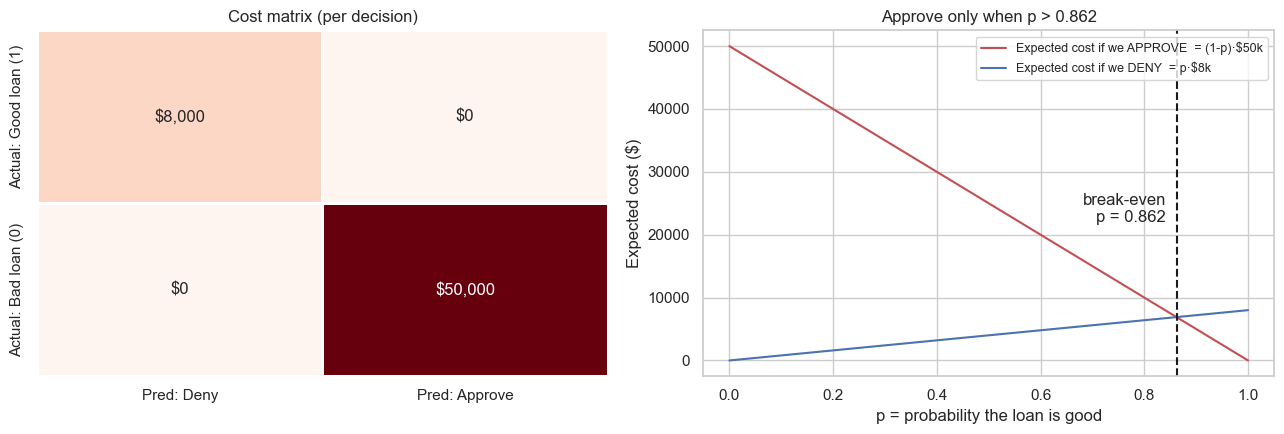

Break-even approval probability: 0.8621


In [2]:
# Visualize the asymmetric cost structure and the break-even threshold
COST_FP = 50_000   # approve a bad loan (default)
COST_FN = 8_000    # deny a good loan (lost profit)
BREAK_EVEN = COST_FP / (COST_FP + COST_FN)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cost_matrix = pd.DataFrame([[COST_FN, 0], [0, COST_FP]],
                           index=["Actual: Good loan (1)", "Actual: Bad loan (0)"],
                           columns=["Pred: Deny", "Pred: Approve"])
annot = np.array([[f"${v:,.0f}" for v in r] for r in cost_matrix.values])
sns.heatmap(cost_matrix, annot=annot, fmt="", cmap="Reds",
            cbar=False, ax=axes[0], linewidths=1, linecolor="white")
axes[0].set_title("Cost matrix (per decision)")

p = np.linspace(0, 1, 201)
axes[1].plot(p, (1 - p) * COST_FP, label="Expected cost if we APPROVE  = (1-p)·$50k", color=PALETTE[0])
axes[1].plot(p, p * COST_FN, label="Expected cost if we DENY  = p·$8k", color=PALETTE[1])
axes[1].axvline(BREAK_EVEN, ls="--", color="k")
axes[1].text(BREAK_EVEN - 0.02, 22_000, f"break-even\np = {BREAK_EVEN:.3f}", ha="right")
axes[1].set_xlabel("p = probability the loan is good")
axes[1].set_ylabel("Expected cost ($)")
axes[1].set_title("Approve only when p > 0.862")
axes[1].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()
print(f"Break-even approval probability: {BREAK_EVEN:.4f}")

In [3]:
# Custom business metric used throughout the notebook
def business_cost(y_true, y_pred, cost_fp=COST_FP, cost_fn=COST_FN):
    """Total dollar cost of a set of decisions (1 = approve, 0 = deny)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    return fp * cost_fp + fn * cost_fn

def cost_per_1000(y_true, y_pred):
    """Business cost normalized to 1,000 applicants so different-sized sets are comparable."""
    return business_cost(y_true, y_pred) / len(y_true) * 1000

def cost_scorer(estimator, X, y, threshold=BREAK_EVEN):
    """sklearn-compatible scorer (higher is better) -> negative cost per 1,000 applicants
    at the theoretical break-even threshold. Written as a plain callable so it works
    across scikit-learn versions."""
    proba = estimator.predict_proba(X)[:, 1]
    return -cost_per_1000(y, (proba >= threshold).astype(int))

def best_threshold(y_true, proba, grid=np.linspace(0.05, 0.99, 189)):
    """Return the threshold that minimizes business cost, plus the full cost curve."""
    costs = np.array([cost_per_1000(y_true, (proba >= t).astype(int)) for t in grid])
    return grid[costs.argmin()], costs.min(), grid, costs

---
# Part 2: Data Understanding & Exploration
## 2.1 Load and inspect

In [4]:
df_raw = pd.read_csv("financial_loan_data.csv")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (20000, 35)


,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,Own,183,0.3544,1,2,0.3583,No,Home,0,29,9,"7,632.0000",1202,146111,19183,"3,329.0000",0.7250,11,126928,0.1997,0.2276,419.8060,0.1811,0,49.0000
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.0878,5,3,0.3303,No,Debt Consolidation,0,21,9,"4,627.0000",3460,53204,9595,"3,309.0833",0.9351,3,43609,0.2070,0.2011,794.0542,0.3899,0,52.0000
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.1374,2,0,0.2447,No,Education,0,20,22,886.0000,895,25176,128874,"3,393.6667",0.8722,6,5205,0.2176,0.2125,666.4067,0.4622,0,52.0000
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,Mortgage,755,0.2676,2,1,0.4362,No,Home,0,27,10,"1,675.0000",1217,104822,5370,"5,757.0000",0.8962,5,99452,0.3004,0.3009,"1,047.5070",0.3131,0,54.0000
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,Mortgage,274,0.3205,0,0,0.0789,No,Debt Consolidation,0,26,27,"1,555.0000",4981,244305,17286,"8,605.3333",0.9414,5,227019,0.1972,0.1760,330.1791,0.0702,1,36.0000


In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCreditLines     200

## 2.2 Data quality audit
The dataset was deliberately made "messy". Each problem is checked below.

In [6]:
# 1) Missing values
missing = df_raw.isna().sum()
missing = missing[missing > 0].to_frame("n_missing")
missing["pct"] = missing["n_missing"] / len(df_raw) * 100
display(missing)

# 2) Columns stored as text that should be numeric / binary
print("AnnualIncome dtype:", df_raw["AnnualIncome"].dtype, "| examples:", df_raw["AnnualIncome"].head(3).tolist())
print("BankruptcyHistory values:", df_raw["BankruptcyHistory"].value_counts().to_dict())

# 3) Duplicates
print("Duplicate rows:", df_raw.duplicated().sum())

# 4) Categorical levels (check for typos / inconsistent casing)
for c in ["EmploymentStatus", "EducationLevel", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]:
    print(f"{c}: {df_raw[c].value_counts(dropna=False).to_dict()}")

,n_missing,pct
EducationLevel,901,4.5050
MaritalStatus,1331,6.6550
SavingsAccountBalance,572,2.8600


AnnualIncome dtype: object | examples: ['$39,948.00', '$39,709.00', '$40,724.00']
BankruptcyHistory values: {'No': 18952, 'Yes': 1048}
Duplicate rows: 0
EmploymentStatus: {'Employed': 17036, 'Self-Employed': 1573, 'Unemployed': 1391}
EducationLevel: {'Bachelor': 5804, 'High School': 5592, 'Associate': 3850, 'Master': 2933, 'Doctorate': 920, nan: 901}
MaritalStatus: {'Married': 9370, 'Single': 5665, 'Divorced': 2704, nan: 1331, 'Widowed': 930}
HomeOwnershipStatus: {'Mortgage': 7939, 'Rent': 6087, 'Own': 3938, 'Other': 2036}
LoanPurpose: {'Home': 5925, 'Debt Consolidation': 5027, 'Auto': 4034, 'Education': 3008, 'Other': 2006}


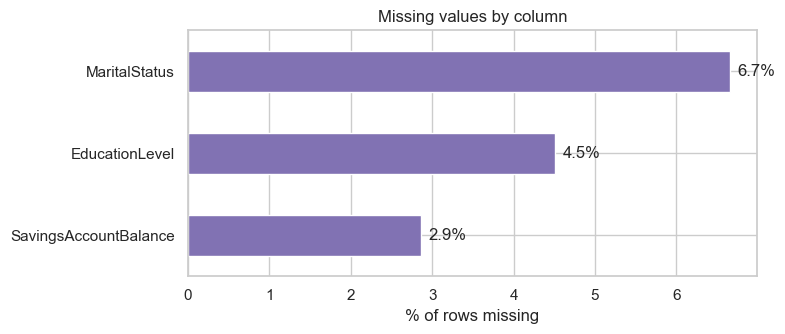

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
missing["pct"].sort_values().plot.barh(ax=ax, color="#8172B3")
ax.set_xlabel("% of rows missing"); ax.set_title("Missing values by column")
for i, v in enumerate(missing["pct"].sort_values()):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.show()

**Data quality findings**

| Issue | Column(s) | Fix (done inside the pipeline so it is reproducible) |
|---|---|---|
| Currency stored as text (`"$39,948.00"`) | `AnnualIncome` | Custom `DataCleaner` transformer strips `$` and `,` and converts to float |
| Yes/No text flag | `BankruptcyHistory` | Mapped to 1/0 by `DataCleaner` |
| Missing values (~4.5%) | `EducationLevel` | Imputation + a "was missing" flag (missingness is informative, see 2.7) |
| Missing values (~6.7%) | `MaritalStatus` | Imputation / "Missing" category |
| Missing values (~2.9%) | `SavingsAccountBalance` | Numeric imputation (median / KNN / iterative compared) |
| No duplicates, no inconsistent category spellings | — | none needed |

For EDA a cleaned copy is created with the same cleaning function the pipeline uses.

In [8]:
def clean_raw(df):
    """Cleaning logic shared by EDA and the DataCleaner pipeline step."""
    df = df.copy()
    if not pd.api.types.is_numeric_dtype(df["AnnualIncome"]):
        df["AnnualIncome"] = (df["AnnualIncome"].astype(str)
                              .str.replace(r"[\$,]", "", regex=True)
                              .replace({"nan": np.nan, "": np.nan})
                              .astype(float))
    if not pd.api.types.is_numeric_dtype(df["BankruptcyHistory"]):
        df["BankruptcyHistory"] = (df["BankruptcyHistory"].astype(str).str.strip().str.lower()
                                   .map({"yes": 1, "no": 0, "1": 1, "0": 0}))
    return df

df = clean_raw(df_raw)
print(df[["AnnualIncome", "BankruptcyHistory"]].dtypes)
df[["AnnualIncome", "BankruptcyHistory"]].describe()

AnnualIncome         float64
BankruptcyHistory      int64
dtype: object


,AnnualIncome,BankruptcyHistory
count,"20,000.0000","20,000.0000"
mean,"59,161.4736",0.0524
std,"40,350.8452",0.2228
min,"15,000.0000",0.0000
25%,"31,679.0000",0.0000
50%,"48,566.0000",0.0000
75%,"74,391.0000",0.0000
max,"485,341.0000",1.0000


## 2.3 Feature categorization

In [9]:
TARGET = "LoanApproved"
REG_TARGET = "RiskScore"

ORDINAL_FEATURES = ["EducationLevel"]
EDU_ORDER = ["High School", "Associate", "Bachelor", "Master", "Doctorate"]
NOMINAL_FEATURES = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]
BINARY_FEATURES = ["BankruptcyHistory", "PreviousLoanDefaults"]
NUMERIC_FEATURES = [c for c in df.columns
                    if c not in ORDINAL_FEATURES + NOMINAL_FEATURES + BINARY_FEATURES + [TARGET, REG_TARGET]]

feature_table = pd.DataFrame(
    [(c, "numeric (continuous/discrete)") for c in NUMERIC_FEATURES] +
    [(c, "binary") for c in BINARY_FEATURES] +
    [(c, "ordinal categorical") for c in ORDINAL_FEATURES] +
    [(c, "nominal categorical") for c in NOMINAL_FEATURES] +
    [(TARGET, "TARGET (classification)"), (REG_TARGET, "TARGET (regression) — excluded from classifier features")],
    columns=["feature", "type"])
print(feature_table["type"].value_counts())
feature_table

type
numeric (continuous/discrete)                              26
nominal categorical                                         4
binary                                                      2
ordinal categorical                                         1
TARGET (classification)                                     1
TARGET (regression) — excluded from classifier features     1
Name: count, dtype: int64


,feature,type
0,Age,numeric (continuous/discrete)
1,AnnualIncome,numeric (continuous/discrete)
2,CreditScore,numeric (continuous/discrete)
3,Experience,numeric (continuous/discrete)
4,LoanAmount,numeric (continuous/discrete)
5,LoanDuration,numeric (continuous/discrete)
6,NumberOfDependents,numeric (continuous/discrete)
7,MonthlyDebtPayments,numeric (continuous/discrete)
8,CreditCardUtilizationRate,numeric (continuous/discrete)
9,NumberOfOpenCreditLines,numeric (continuous/discrete)


## 2.4 Target distribution & class imbalance

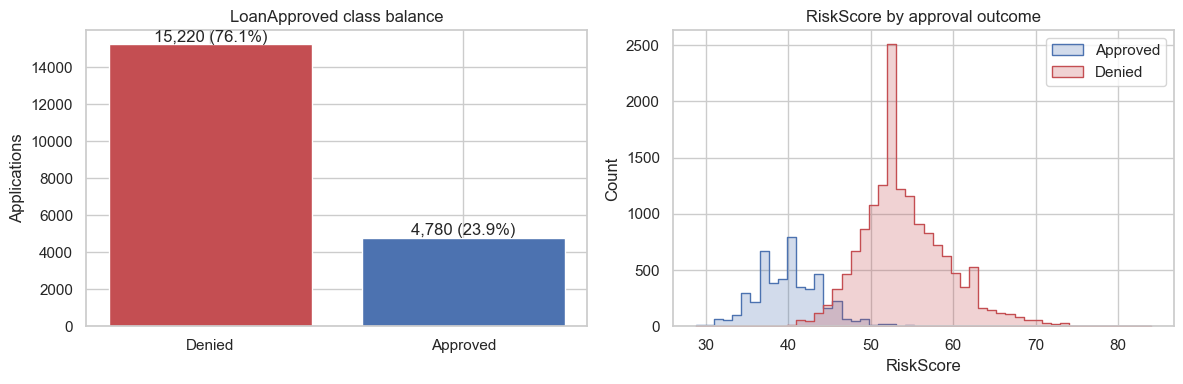

Imbalance ratio (denied : approved) = 3.18 : 1
Point-biserial correlation RiskScore vs LoanApproved: -0.766


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df[TARGET].value_counts().sort_index()
axes[0].bar([LABELS[i] for i in counts.index], counts.values, color=[PALETTE[i] for i in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 150, f"{v:,} ({v/len(df):.1%})", ha="center")
axes[0].set_title("LoanApproved class balance"); axes[0].set_ylabel("Applications")

sns.histplot(data=df, x=REG_TARGET, hue=TARGET, palette=PALETTE, bins=50, ax=axes[1], element="step")
axes[1].set_title("RiskScore by approval outcome")
axes[1].legend(title="", labels=["Approved", "Denied"])
plt.tight_layout(); plt.show()

print(f"Imbalance ratio (denied : approved) = {counts[0]/counts[1]:.2f} : 1")
print("Point-biserial correlation RiskScore vs LoanApproved:",
      round(stats.pointbiserialr(df[TARGET], df[REG_TARGET])[0], 3))

**Interpretation.** Only **23.9%** of applications are approved (≈3.2 : 1 imbalance). Consequences:
* Accuracy is misleading (a "deny all" model scores 76%) → use cost, precision/recall, PR-AUC.
* Use **stratified** splits and stratified K-fold CV so every fold keeps the 24/76 ratio.
* Class weighting is tested as a hyperparameter; the decision threshold is tuned on cost.

`RiskScore` separates the classes almost perfectly (approved ≈ 40, denied ≈ 54). This confirms it is a near-copy of the
label and must not be a feature of the classifier (leakage).

## 2.5 Univariate analysis — numeric distributions & outliers

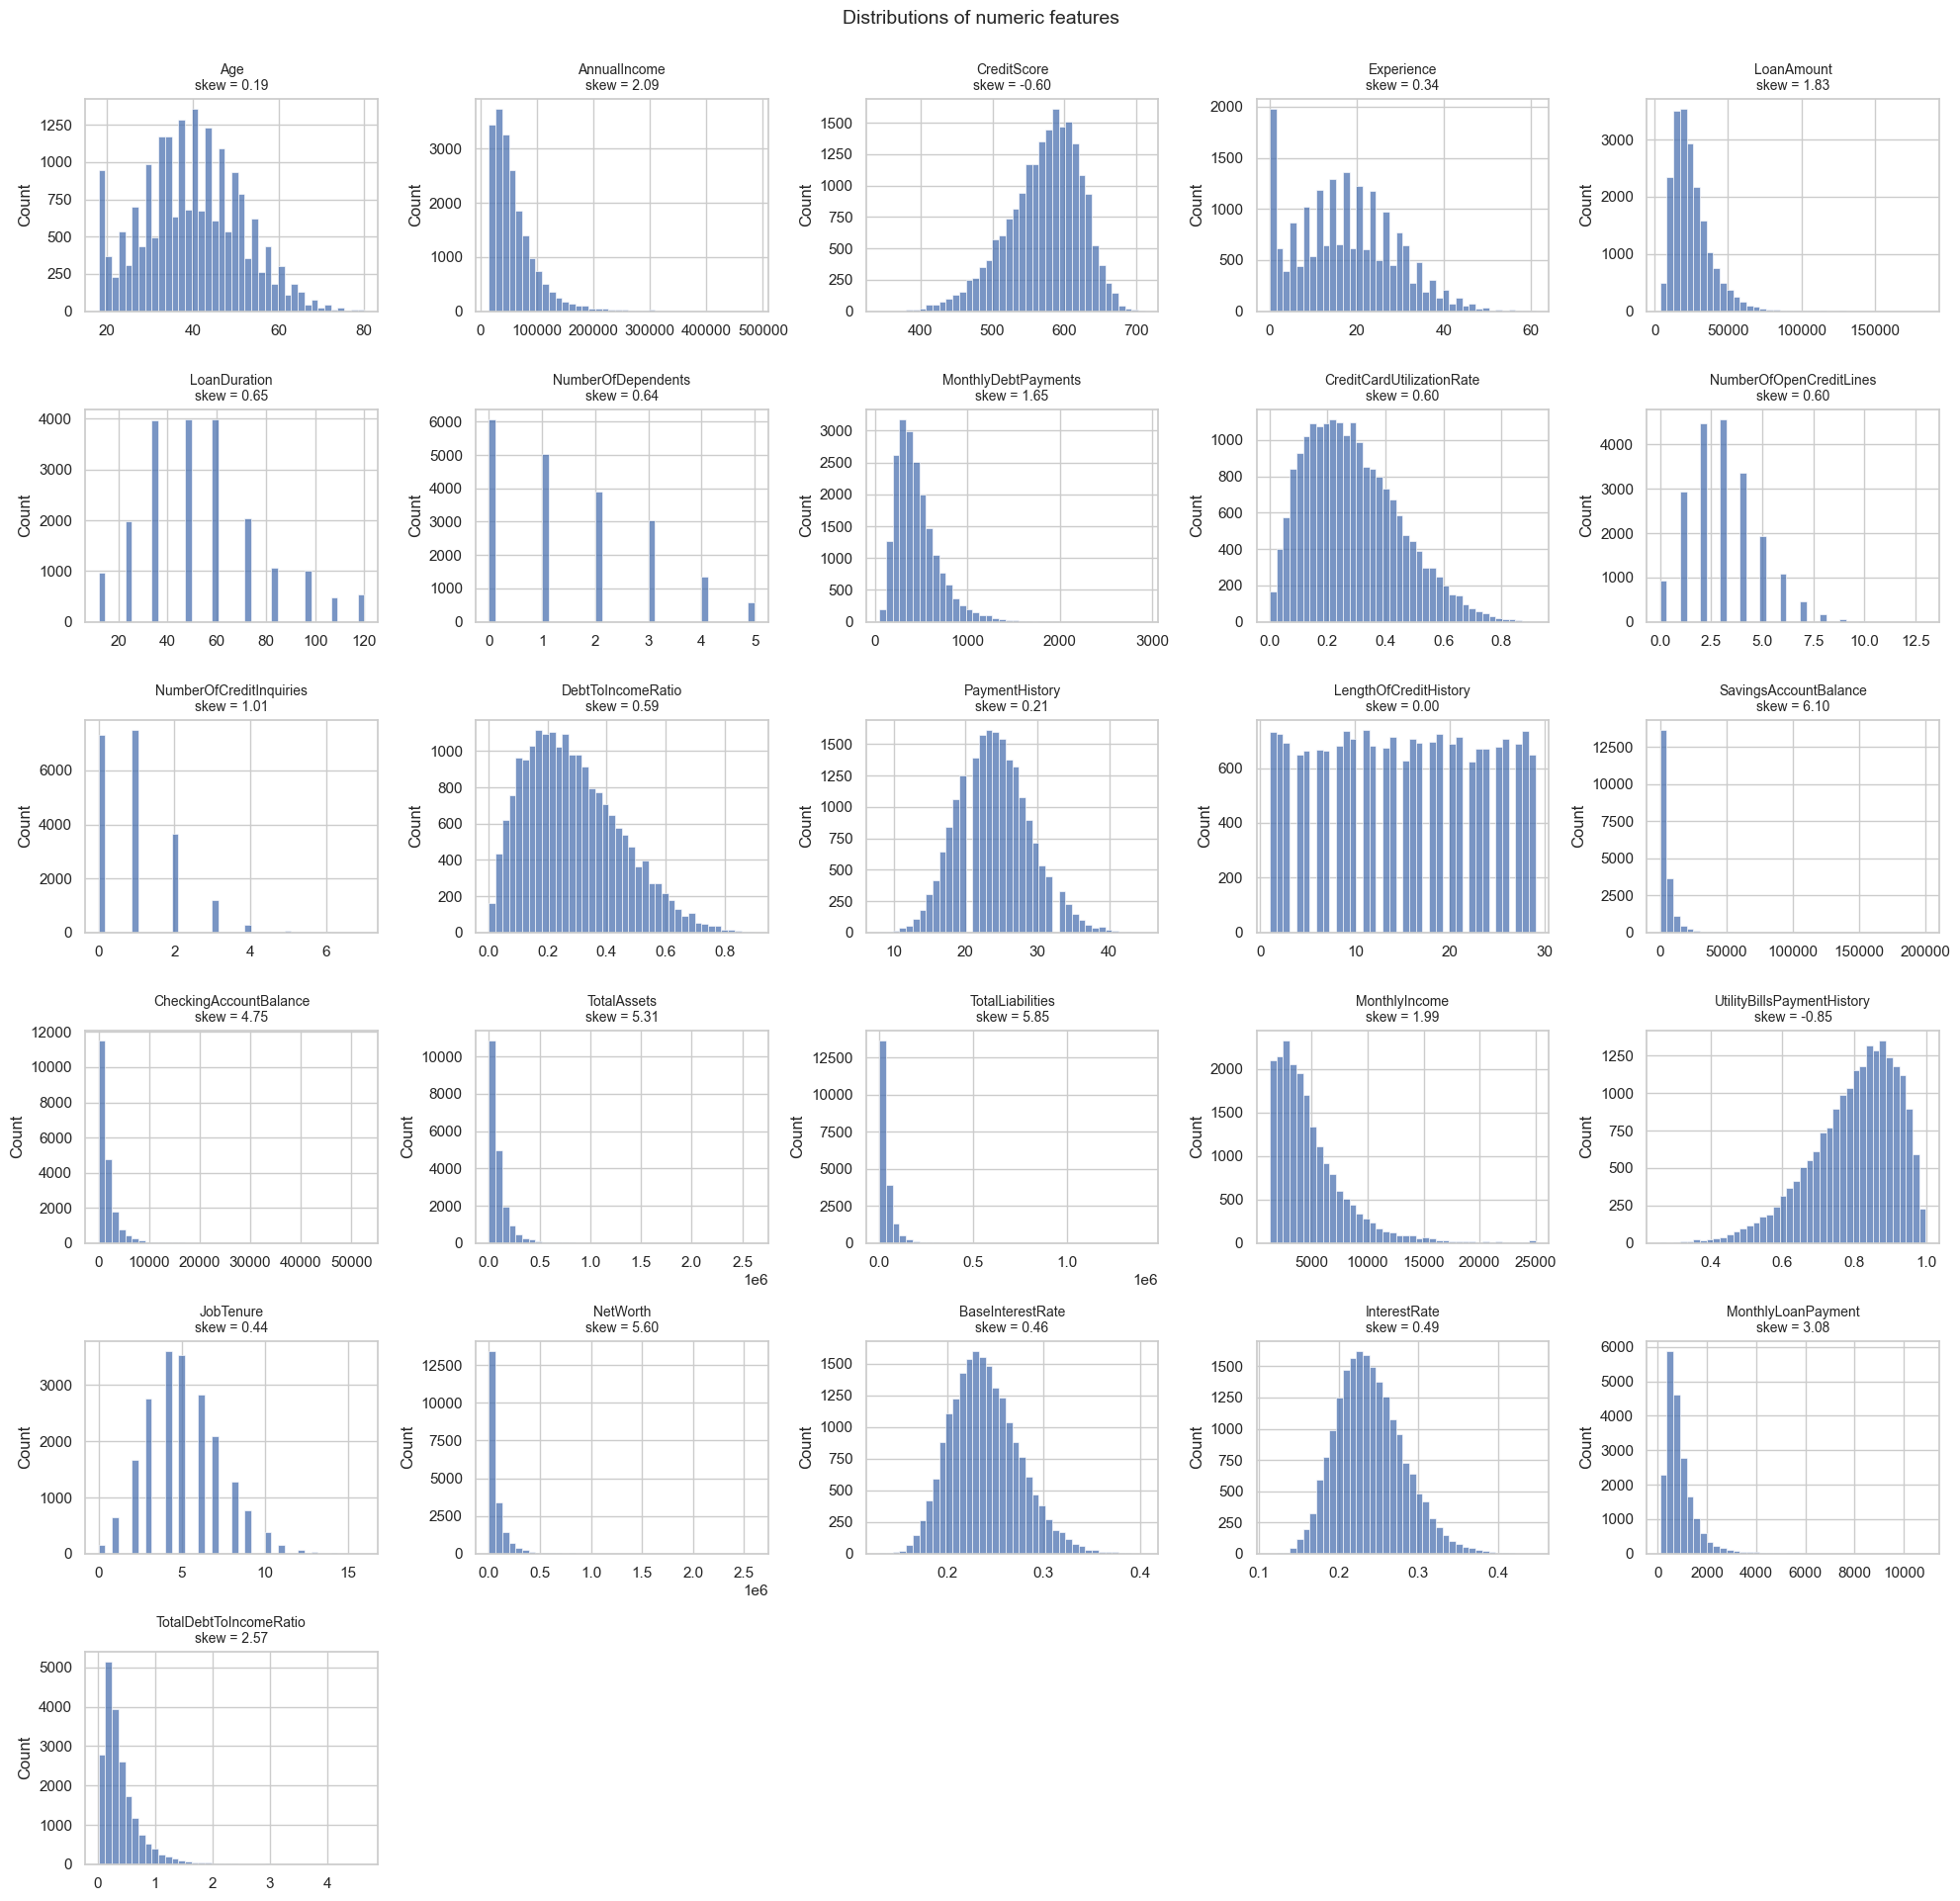

In [11]:
num_for_plot = NUMERIC_FEATURES
n = len(num_for_plot); ncols = 5; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.2 * nrows))
for ax, c in zip(axes.flat, num_for_plot):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, color="#4C72B0")
    ax.set_title(f"{c}\nskew = {df[c].skew():.2f}", fontsize=10); ax.set_xlabel("")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.suptitle("Distributions of numeric features", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

In [12]:
# Outlier detection with the IQR rule
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_tbl = pd.DataFrame({
    "skew": df[NUMERIC_FEATURES].skew(),
    "n_outliers_IQR": [iqr_outliers(df[c].dropna()) for c in NUMERIC_FEATURES],
}).assign(pct_outliers=lambda t: t["n_outliers_IQR"] / len(df) * 100).sort_values("skew", ascending=False)
display(outlier_tbl.head(15))

SKEWED_FEATURES = outlier_tbl.index[outlier_tbl["skew"] > 1].tolist()
print("Highly right-skewed features (skew > 1):", SKEWED_FEATURES)

,skew,n_outliers_IQR,pct_outliers
SavingsAccountBalance,6.0961,1547,7.7350
TotalLiabilities,5.8489,1533,7.6650
NetWorth,5.5998,1564,7.8200
TotalAssets,5.3113,1442,7.2100
CheckingAccountBalance,4.7461,1522,7.6100
MonthlyLoanPayment,3.0818,1089,5.4450
TotalDebtToIncomeRatio,2.5745,1152,5.7600
AnnualIncome,2.0889,947,4.7350
MonthlyIncome,1.9929,925,4.6250
LoanAmount,1.8337,746,3.7300


Highly right-skewed features (skew > 1): ['SavingsAccountBalance', 'TotalLiabilities', 'NetWorth', 'TotalAssets', 'CheckingAccountBalance', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'AnnualIncome', 'MonthlyIncome', 'LoanAmount', 'MonthlyDebtPayments', 'NumberOfCreditInquiries']


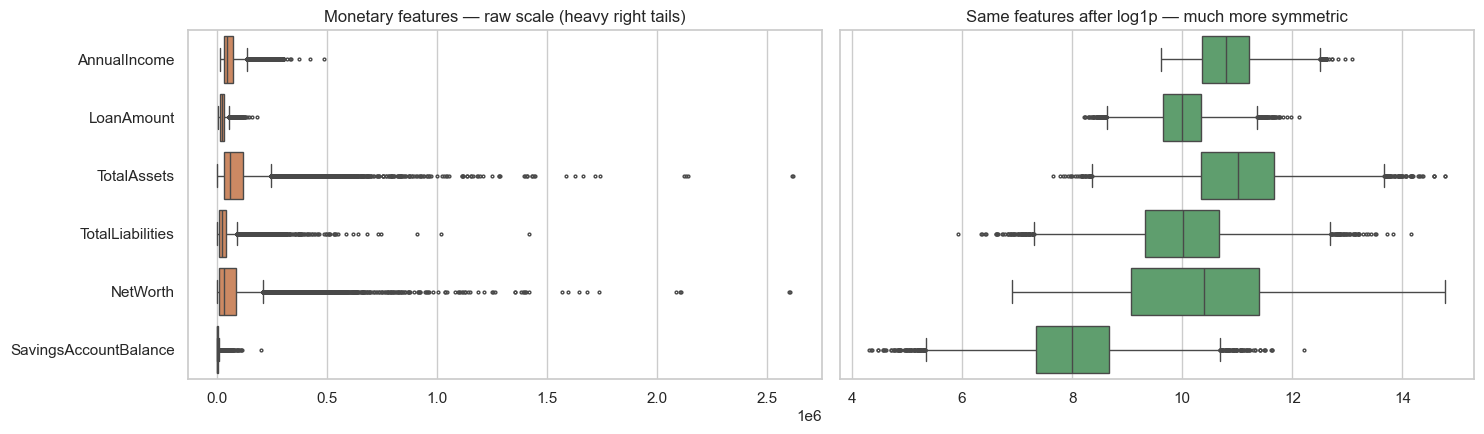

In [13]:
money_cols = ["AnnualIncome", "LoanAmount", "TotalAssets", "TotalLiabilities", "NetWorth", "SavingsAccountBalance"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df[money_cols], orient="h", ax=axes[0], color="#DD8452", fliersize=2)
axes[0].set_title("Monetary features — raw scale (heavy right tails)")
sns.boxplot(data=np.log1p(df[money_cols]), orient="h", ax=axes[1], color="#55A868", fliersize=2)
axes[1].set_title("Same features after log1p — much more symmetric")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Outlier decision.** The outliers are large but **plausible** values (wealthy applicants, big loans) — not data-entry
errors — and they carry real signal, so they are **kept**. A **log1p transform** of the skewed monetary features is
built into the pipeline as an *option* and tested in Part 3 (tree models are not sensitive to scale either way).

## 2.6 Bivariate analysis — numeric features vs. target

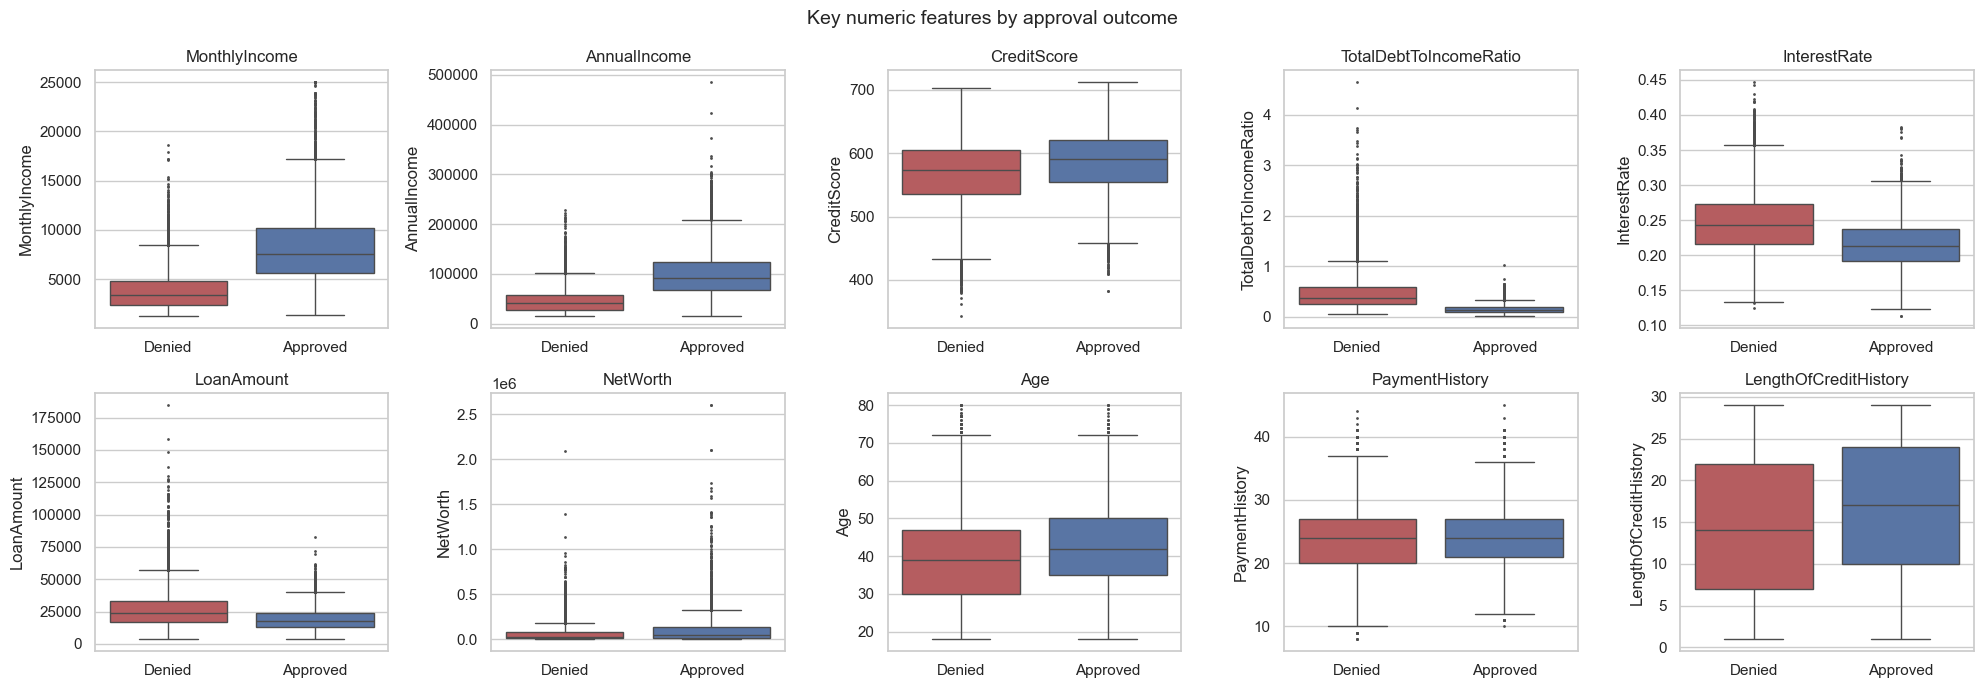

In [14]:
key_num = ["MonthlyIncome", "AnnualIncome", "CreditScore", "TotalDebtToIncomeRatio", "InterestRate",
           "LoanAmount", "NetWorth", "Age", "PaymentHistory", "LengthOfCreditHistory"]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.flat, key_num):
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=PALETTE, legend=False, ax=ax, fliersize=1)
    ax.set_xticklabels(["Denied", "Approved"]); ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Key numeric features by approval outcome", fontsize=14)
plt.tight_layout(); plt.show()

In [15]:
# Statistical tests: Mann-Whitney U (non-parametric; distributions are skewed / non-normal)
# plus a normality check (D'Agostino K^2) that justifies using a non-parametric test.
rows = []
for c in NUMERIC_FEATURES + BINARY_FEATURES:
    a = df.loc[df[TARGET] == 1, c].dropna(); b = df.loc[df[TARGET] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rank_biserial = 1 - 2 * u / (len(a) * len(b))          # effect size in [-1, 1]
    normal_p = stats.normaltest(df[c].dropna())[1]
    rows.append((c, a.median(), b.median(), p, -rank_biserial, normal_p))
tests = (pd.DataFrame(rows, columns=["feature", "median_approved", "median_denied", "mannwhitney_p",
                                     "effect_size(rank-biserial)", "normality_p"])
         .assign(abs_effect=lambda t: t.iloc[:, 4].abs())
         .sort_values("abs_effect", ascending=False).drop(columns="abs_effect"))
tests["significant (p<0.05)"] = tests["mannwhitney_p"] < 0.05
print(f"{(tests['normality_p'] < 0.05).sum()} of {len(tests)} features reject normality -> non-parametric test is appropriate")
tests.reset_index(drop=True)

28 of 28 features reject normality -> non-parametric test is appropriate


,feature,median_approved,median_denied,mannwhitney_p,effect_size(rank-biserial),normality_p,significant (p<0.05)
0,TotalDebtToIncomeRatio,0.1376,0.3809,0.0000,-0.8128,0.0000,True
1,MonthlyIncome,"7,572.2917","3,365.6667",0.0000,0.7700,0.0000,True
2,AnnualIncome,"91,269.5000","40,557.5000",0.0000,0.7674,0.0000,True
3,InterestRate,0.2136,0.2429,0.0000,-0.4169,0.0000,True
4,LoanAmount,"17,336.5000","23,566.0000",0.0000,-0.3522,0.0000,True
5,BaseInterestRate,0.2209,0.2411,0.0000,-0.3372,0.0000,True
6,MonthlyLoanPayment,576.0348,791.2212,0.0000,-0.3008,0.0000,True
7,Experience,20.0000,16.0000,0.0000,0.1957,0.0000,True
8,Age,42.0000,39.0000,0.0000,0.1941,0.0000,True
9,CreditScore,591.0000,574.0000,0.0000,0.1933,0.0000,True


## 2.7 Categorical features vs. target (+ chi-square tests)

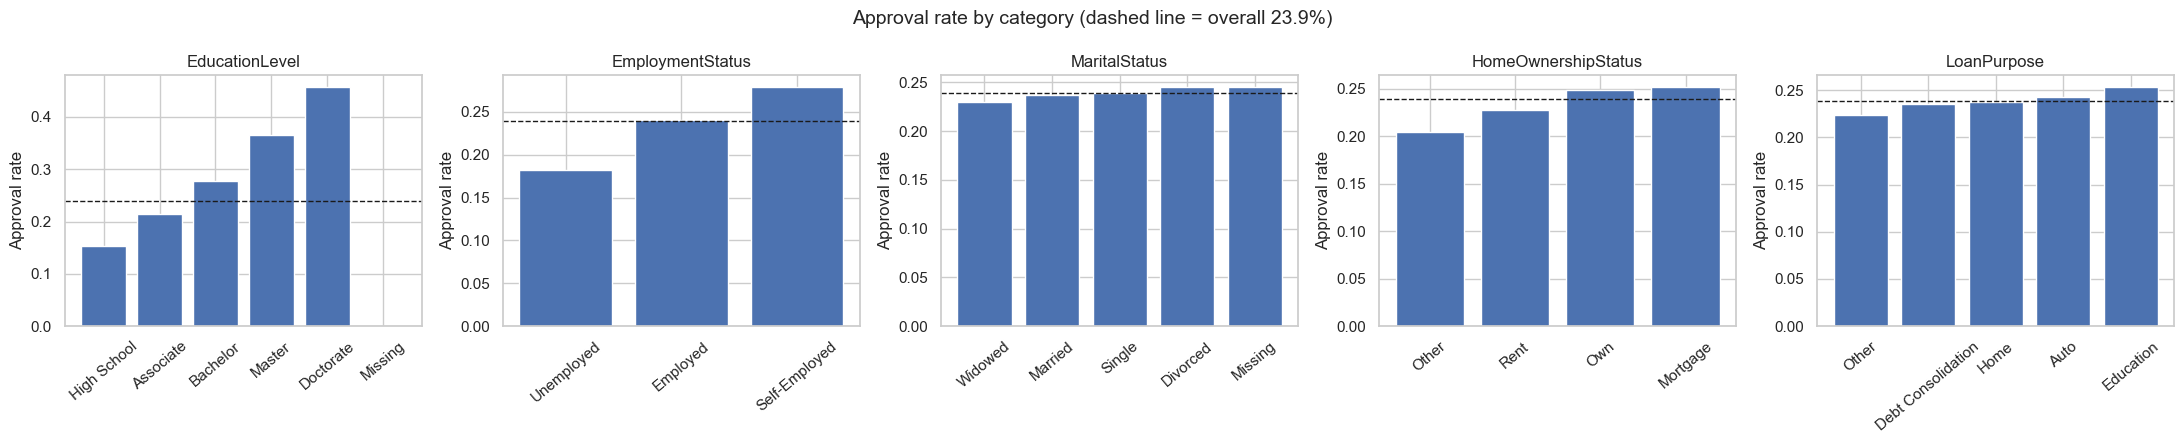

,feature,chi2,dof,p_value,Cramer's V
0,EducationLevel,"1,068.9276",5,0.0000,0.2312
1,EmploymentStatus,38.5065,2,0.0000,0.0439
3,HomeOwnershipStatus,26.3288,3,0.0000,0.0363
4,LoanPurpose,6.6957,4,0.1529,0.0183
2,MaritalStatus,1.3740,4,0.8487,0.0083


In [16]:
cat_cols = ORDINAL_FEATURES + NOMINAL_FEATURES
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
chi_rows = []
for ax, c in zip(axes, cat_cols):
    tmp = df[[c, TARGET]].copy(); tmp[c] = tmp[c].fillna("Missing")
    order = EDU_ORDER + ["Missing"] if c == "EducationLevel" else tmp.groupby(c)[TARGET].mean().sort_values().index
    rate = tmp.groupby(c)[TARGET].mean().reindex(order)
    ax.bar(rate.index.astype(str), rate.values, color="#4C72B0")
    ax.axhline(df[TARGET].mean(), ls="--", color="k", lw=1)
    ax.set_title(c); ax.set_ylabel("Approval rate"); ax.tick_params(axis="x", rotation=40)
    ct = pd.crosstab(tmp[c], tmp[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    chi_rows.append((c, chi2, dof, p, cramers_v))
plt.suptitle("Approval rate by category (dashed line = overall 23.9%)", fontsize=14)
plt.tight_layout(); plt.show()
pd.DataFrame(chi_rows, columns=["feature", "chi2", "dof", "p_value", "Cramer's V"]).sort_values("Cramer's V", ascending=False)

**Interpretation.** `EmploymentStatus` and `EducationLevel` are clearly associated with approval (unemployed applicants
are approved much less often; approval rises with education). `MaritalStatus`/`HomeOwnershipStatus`/`LoanPurpose` show
weaker effects (`MaritalStatus` and `LoanPurpose` are not statistically significant).

**Important missing-data finding:** rows with a **missing `EducationLevel` were never approved (0% of 901)**, while
missing `MaritalStatus` (24%) and missing `SavingsAccountBalance` (26%) look like the overall rate. So
`EducationLevel` is **missing *not* at random** — the gap itself carries information (an incomplete application
was always denied). Simply filling it with the most common value ("Bachelor") would hide that signal and even make
those applicants look *better*. This is tested in Part 3 with explicit missing-value indicator columns.

Note: `MaritalStatus`, age and similar attributes are **protected or sensitive** characteristics under fair-lending
law (ECOA). They are kept here for analysis, and segment-level error rates are audited in Part 5.

## 2.8 Multivariate analysis — correlation matrix

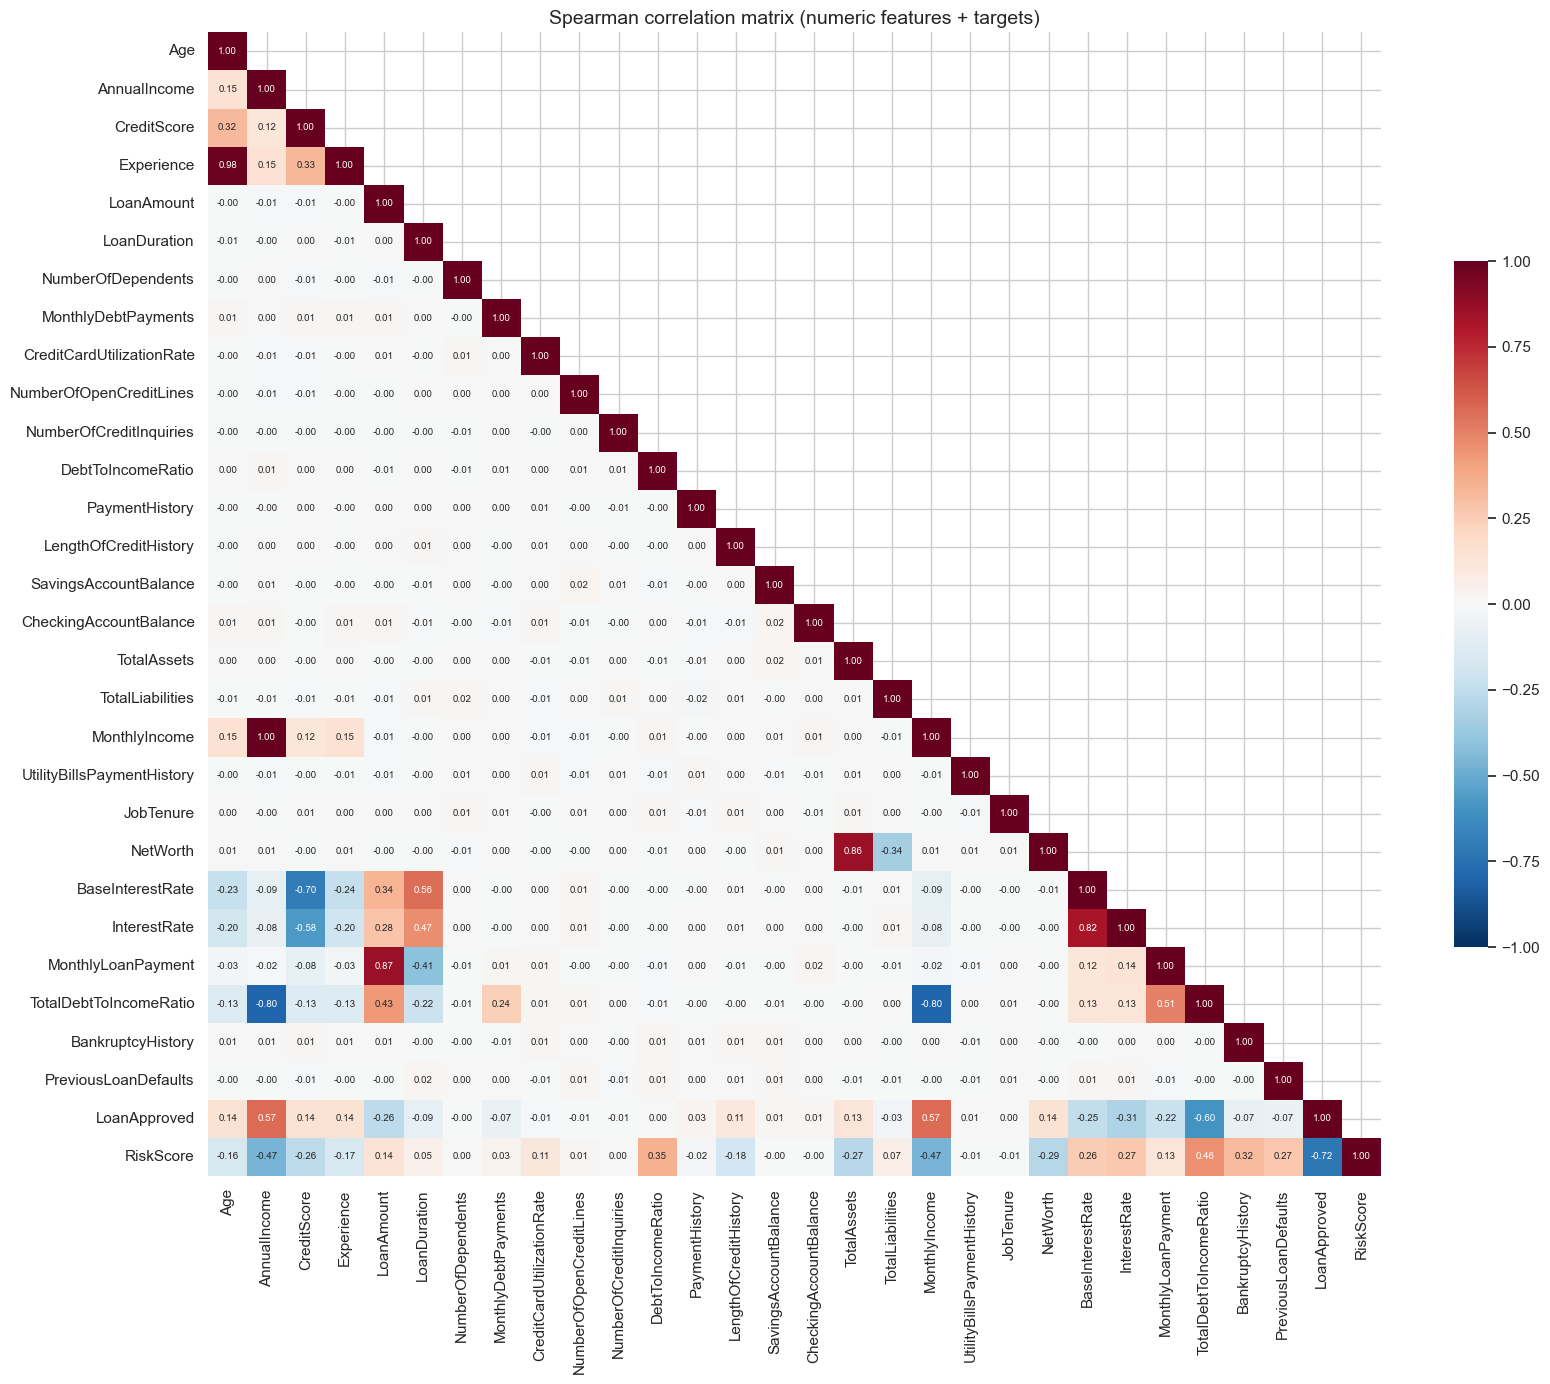

In [17]:
corr = df[NUMERIC_FEATURES + BINARY_FEATURES + [TARGET, REG_TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(17, 14))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .6})
ax.set_title("Spearman correlation matrix (numeric features + targets)", fontsize=14)
plt.tight_layout(); plt.show()

In [18]:
print("Correlation with LoanApproved (Spearman):")
display(corr[TARGET].drop([TARGET, REG_TARGET]).sort_values(key=abs, ascending=False).head(12).to_frame())

# Highly collinear pairs (|rho| > 0.8)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().query("abs(rho) > 0.8").sort_values("rho", key=abs, ascending=False))
print("Highly correlated feature pairs (|rho| > 0.8):")
pairs

Correlation with LoanApproved (Spearman):


,LoanApproved
TotalDebtToIncomeRatio,-0.6004
MonthlyIncome,0.5688
AnnualIncome,0.5669
InterestRate,-0.3080
LoanAmount,-0.2602
BaseInterestRate,-0.2491
MonthlyLoanPayment,-0.2222
Experience,0.1446
Age,0.1434
CreditScore,0.1428


Highly correlated feature pairs (|rho| > 0.8):


,level_0,level_1,rho
45,AnnualIncome,MonthlyIncome,0.9962
2,Age,Experience,0.9847
129,LoanAmount,MonthlyLoanPayment,0.8667
348,TotalAssets,NetWorth,0.8602
407,BaseInterestRate,InterestRate,0.8206
375,MonthlyIncome,TotalDebtToIncomeRatio,-0.8031
52,AnnualIncome,TotalDebtToIncomeRatio,-0.8001


**Interpretation.**
* **Income** (`MonthlyIncome`/`AnnualIncome`) is the strongest positive driver of approval; **`TotalDebtToIncomeRatio`**,
  **`InterestRate`/`BaseInterestRate`** and `LoanAmount` relative to income are the strongest negative drivers.
  Credit score matters less than expected in this data.
* **Multicollinearity:** `AnnualIncome`≈`MonthlyIncome`, `Age`≈`Experience`, `TotalAssets`≈`NetWorth`,
  `BaseInterestRate`≈`InterestRate`, `LoanAmount`≈`MonthlyLoanPayment`. This matters for **logistic-regression coefficient
  interpretation** (handled with L2/L1 regularization and feature selection); tree models are unaffected.

## 2.9 Pair plot of the strongest drivers

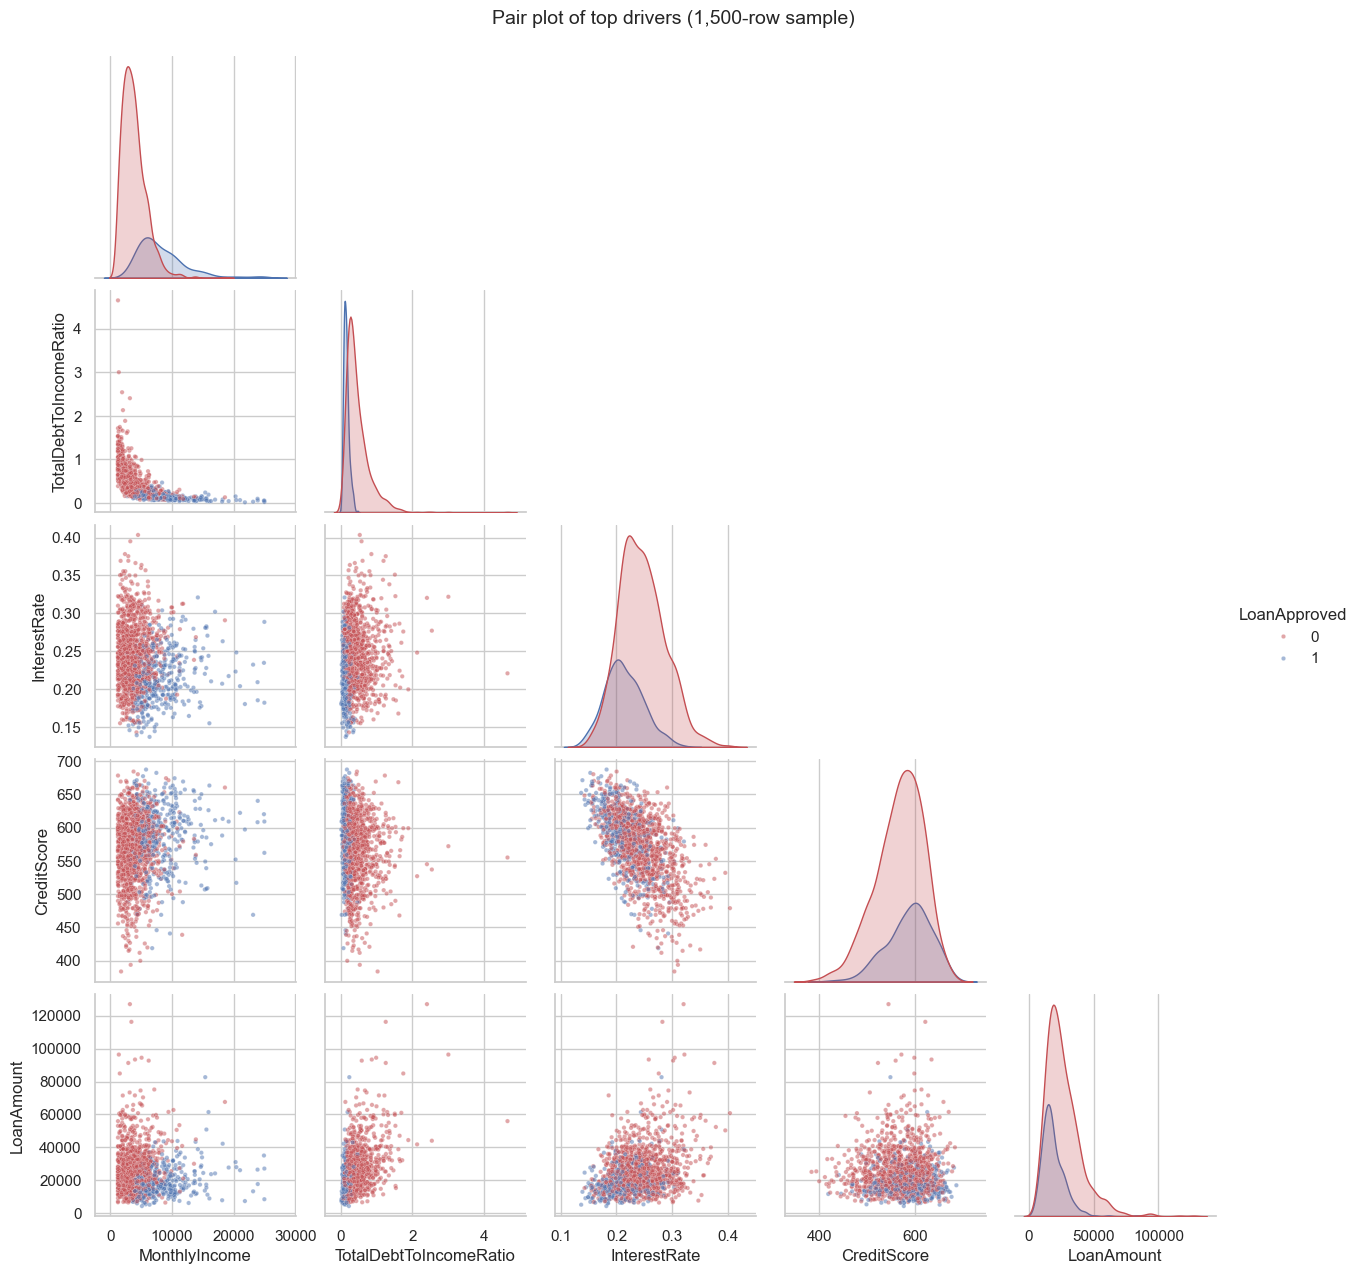

In [19]:
pp_cols = ["MonthlyIncome", "TotalDebtToIncomeRatio", "InterestRate", "CreditScore", "LoanAmount"]
sample = df.sample(1500, random_state=RANDOM_STATE)
g = sns.pairplot(sample[pp_cols + [TARGET]], hue=TARGET, palette=PALETTE, corner=True,
                 plot_kws={"s": 10, "alpha": 0.5}, diag_kind="kde")
g.figure.suptitle("Pair plot of top drivers (1,500-row sample)", y=1.02, fontsize=14)
plt.show()

**Interpretation.** Approved loans (blue) sit in the **high-income / low debt-to-income / low interest-rate** corner. The
boundary is **non-linear** (e.g., approval depends on income *relative to* loan size and debt), which suggests that
(a) ratio features may help and (b) tree ensembles may beat a purely linear model.

## 2.10 Feature engineering opportunities (documented, implemented in Part 3)
| New feature | Formula | Why |
|---|---|---|
| `LoanToIncome` | LoanAmount / AnnualIncome | Size of the loan relative to ability to pay |
| `PaymentToIncome` | MonthlyLoanPayment / MonthlyIncome | Monthly burden of the new loan alone |
| `AssetToLiability` | TotalAssets / (TotalLiabilities + 1) | Balance-sheet strength |
| `LiquidReserveMonths` | (Savings + Checking) / MonthlyDebtPayments | Months of debt payments covered by cash |
| `CreditUtilXInquiries` | CreditCardUtilizationRate × (NumberOfCreditInquiries + 1) | Credit-hungry behavior signal |
| `RateSpread` | InterestRate − BaseInterestRate | Risk premium the lender already priced in |

Log-transforming the skewed monetary columns and adding "was missing" flags are also tested as pipeline parameters.

---
# Part 3: Pipeline Development (Data Preparation)

All preprocessing is done **inside a scikit-learn `Pipeline`**, fitted only on training folds — so there is no data
leakage from the test set, and the exact same steps run in production on raw application data (including the
`"$39,948.00"` text format).

```
Pipeline
 ├─ DataCleaner        (custom)  "$39,948.00" -> 39948.0 ; Yes/No -> 1/0
 ├─ FeatureEngineer    (custom)  adds 6 ratio / interaction features
 ├─ Preprocessor       (custom wrapper so the options below are tunable)
 │  ColumnTransformer
 │    ├─ skewed numeric : imputer -> optional log1p -> StandardScaler
 │    ├─ other numeric  : imputer -> StandardScaler
 │    ├─ binary         : most_frequent imputer (passthrough 0/1)
 │    ├─ ordinal        : imputer -> OrdinalEncoder(High School < ... < Doctorate) -> scaler
 │    ├─ nominal        : imputer -> OneHotEncoder(handle_unknown="ignore")
 │    └─ missing flags  : (optional) 1/0 "was missing" columns
 ├─ SelectKBest        feature selection (k is tuned)
 └─ model
```
## 3.1 Train / test split

In [20]:
X = df_raw.drop(columns=[TARGET, REG_TARGET])   # RAW data: the pipeline does all the cleaning
y = df_raw[TARGET].astype(int)
y_risk = df_raw[REG_TARGET]

X_train, X_test, y_train, y_test, yr_train, yr_test = train_test_split(
    X, y, y_risk, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"approved {y_train.mean():.3f}")
print("Test: ", X_test.shape, f"approved {y_test.mean():.3f}")

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (16000, 33) approved 0.239
Test:  (4000, 33) approved 0.239


## 3.2 Custom transformers

In [21]:
class DataCleaner(BaseEstimator, TransformerMixin):
    """Fixes the 'messy' raw formats: currency strings -> float, Yes/No -> 1/0.
    Stateless, so it is safe to use on any new application data."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return clean_raw(pd.DataFrame(X))


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds ratio / interaction features identified during EDA.
    `add_features` can be switched off to measure the value of feature engineering."""
    NEW_FEATURES = ["LoanToIncome", "PaymentToIncome", "AssetToLiability",
                    "LiquidReserveMonths", "CreditUtilXInquiries", "RateSpread"]

    def __init__(self, add_features=True):
        self.add_features = add_features
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        if self.add_features:
            X["LoanToIncome"] = X["LoanAmount"] / X["AnnualIncome"]
            X["PaymentToIncome"] = X["MonthlyLoanPayment"] / X["MonthlyIncome"]
            X["AssetToLiability"] = X["TotalAssets"] / (X["TotalLiabilities"] + 1)
            # Savings may be missing -> result is NaN and is imputed later in the ColumnTransformer
            X["LiquidReserveMonths"] = (X["SavingsAccountBalance"] + X["CheckingAccountBalance"]) / X["MonthlyDebtPayments"]
            X["CreditUtilXInquiries"] = X["CreditCardUtilizationRate"] * (X["NumberOfCreditInquiries"] + 1)
            X["RateSpread"] = X["InterestRate"] - X["BaseInterestRate"]
        else:
            for c in self.NEW_FEATURES:      # keep columns so the ColumnTransformer layout stays fixed
                X[c] = 0.0
        return X


# quick test of the custom steps on raw rows
demo = FeatureEngineer().fit_transform(DataCleaner().fit_transform(X_train.head(3)))
demo[["AnnualIncome", "BankruptcyHistory"] + FeatureEngineer.NEW_FEATURES]

,AnnualIncome,BankruptcyHistory,LoanToIncome,PaymentToIncome,AssetToLiability,LiquidReserveMonths,CreditUtilXInquiries,RateSpread
15234,"34,402.0000",0,0.4758,0.2295,4.2254,19.8714,0.6847,0.0088
15766,"51,561.0000",0,0.4834,0.1498,1.4140,1.5589,0.2460,0.0141
16912,"119,497.0000",0,0.2375,0.0828,11.8110,20.0507,0.2763,-0.0224


## 3.3 ColumnTransformer and pipeline factory

In [22]:
ENGINEERED = FeatureEngineer.NEW_FEATURES
SKEWED_ALL = sorted(set(SKEWED_FEATURES) | {"LoanToIncome", "AssetToLiability", "LiquidReserveMonths", "PaymentToIncome"})
SKEWED_ALL = [c for c in SKEWED_ALL if c not in BINARY_FEATURES]
OTHER_NUMERIC = [c for c in NUMERIC_FEATURES + ENGINEERED if c not in SKEWED_ALL]

def safe_log1p(X):
    """log1p that is safe for small negative values (ratios are >= 0 in practice)."""
    return np.log1p(np.clip(X, 0, None))

def missing_flags(X):
    """1/0 indicator columns: was the value missing?"""
    return pd.DataFrame(X).isna().astype(int).values

def missing_flag_names(transformer, input_features):
    return np.array([f"{c}_was_missing" for c in input_features], dtype=object)

def make_numeric_imputer(strategy):
    if strategy == "knn":
        return KNNImputer(n_neighbors=5)
    if strategy == "iterative":
        return IterativeImputer(max_iter=10, random_state=RANDOM_STATE)
    return SimpleImputer(strategy=strategy)

def build_preprocessor(num_impute="median", cat_impute="most_frequent", log_skewed=True, add_indicator=False):
    skewed_pipe = Pipeline([
        ("impute", make_numeric_imputer(num_impute)),
        ("log", FunctionTransformer(safe_log1p) if log_skewed else "passthrough"),
        ("scale", StandardScaler())])
    numeric_pipe = Pipeline([
        ("impute", make_numeric_imputer(num_impute)),
        ("scale", StandardScaler())])
    binary_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
    cat_imputer = (SimpleImputer(strategy="constant", fill_value="Missing")
                   if cat_impute == "constant" else SimpleImputer(strategy="most_frequent"))
    ordinal_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(categories=[EDU_ORDER], handle_unknown="use_encoded_value", unknown_value=-1)),
        ("scale", StandardScaler())])
    nominal_pipe = Pipeline([
        ("impute", cat_imputer),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    transformers = [
        ("skewed", skewed_pipe, SKEWED_ALL),
        ("numeric", numeric_pipe, OTHER_NUMERIC),
        ("binary", binary_pipe, BINARY_FEATURES),
        ("ordinal", ordinal_pipe, ORDINAL_FEATURES),
        ("nominal", nominal_pipe, NOMINAL_FEATURES)]
    if add_indicator:   # explicit "was missing" flags for the 3 columns that have gaps
        transformers.append(("missing_flags", FunctionTransformer(missing_flags, feature_names_out=missing_flag_names),
                             ["EducationLevel", "MaritalStatus", "SavingsAccountBalance"]))
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)

class Preprocessor(BaseEstimator, TransformerMixin):
    """Custom wrapper around the ColumnTransformer so that preprocessing choices
    (imputer, log transform, missing flags) become tunable hyperparameters in grid search."""
    def __init__(self, num_impute="median", cat_impute="most_frequent", log_skewed=True, add_indicator=False):
        self.num_impute = num_impute
        self.cat_impute = cat_impute
        self.log_skewed = log_skewed
        self.add_indicator = add_indicator
    def fit(self, X, y=None):
        self.ct_ = build_preprocessor(self.num_impute, self.cat_impute, self.log_skewed, self.add_indicator).fit(X, y)
        return self
    def transform(self, X):
        return self.ct_.transform(X)
    def get_feature_names_out(self, input_features=None):
        return self.ct_.get_feature_names_out()

DEFAULT_PREP = dict(num_impute="median", cat_impute="most_frequent", log_skewed=True, add_indicator=False)

def build_pipeline(model, k="all", score_func=f_classif, add_features=True, **prep_kwargs):
    prep_kwargs = {**DEFAULT_PREP, **prep_kwargs}   # defaults are updated after the experiments below
    return Pipeline([
        ("clean", DataCleaner()),
        ("features", FeatureEngineer(add_features=add_features)),
        ("prep", Preprocessor(**prep_kwargs)),
        ("select", SelectKBest(score_func=score_func, k=k)),
        ("model", model)])

base_pipe = build_pipeline(LogisticRegression(max_iter=2000))
Xt = base_pipe[:-2].fit_transform(X_train)
print("Columns after preprocessing:", Xt.shape[1], "| any NaN left:", np.isnan(Xt).any())
base_pipe

Columns after preprocessing: 51 | any NaN left: False


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clean', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,add_features,True
,num_impute,'median'
,cat_impute,'most_frequent'
,log_skewed,True
,add_indicator,False
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",'all'
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...0022145080E00>


## 3.4 Comparing imputation strategies
Missing values are only ~3–7% per column, but the choice should be evidence-based. Each strategy is scored with the
same logistic-regression model and 5-fold stratified CV.

In [23]:
def oof_metrics(pipe, X_, y_, name):
    """Out-of-fold probabilities via 5-fold CV -> threshold-free metrics + cost at best threshold."""
    t0 = time.time()
    proba = cross_val_predict(pipe, X_, y_, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    secs = time.time() - t0
    thr, best_cost, _, _ = best_threshold(y_, proba)
    return {"model": name, "ROC_AUC": roc_auc_score(y_, proba), "PR_AUC": average_precision_score(y_, proba),
            "Brier": brier_score_loss(y_, proba),
            "cost/1k @0.5": cost_per_1000(y_, (proba >= 0.5).astype(int)),
            "cost/1k @0.862": cost_per_1000(y_, (proba >= BREAK_EVEN).astype(int)),
            "best_thr": thr, "cost/1k @best": best_cost, "cv_seconds": secs}, proba

imputation_configs = {
    "median + most_frequent":            dict(num_impute="median", cat_impute="most_frequent"),
    "mean + most_frequent":              dict(num_impute="mean", cat_impute="most_frequent"),
    "median + 'Missing' category":       dict(num_impute="median", cat_impute="constant"),
    "KNN(5) + most_frequent":            dict(num_impute="knn", cat_impute="most_frequent"),
    "Iterative (MICE) + most_frequent":  dict(num_impute="iterative", cat_impute="most_frequent"),
    "median + most_frequent + flags":    dict(num_impute="median", cat_impute="most_frequent", add_indicator=True),
}
imp_rows = []
for name, cfg in imputation_configs.items():
    pipe = build_pipeline(LogisticRegression(max_iter=2000), **cfg)
    m, _ = oof_metrics(pipe, X_train, y_train, name)
    imp_rows.append(m)
imputation_results = pd.DataFrame(imp_rows).set_index("model")
imputation_results

,ROC_AUC,PR_AUC,Brier,cost/1k @0.5,cost/1k @0.862,best_thr,cost/1k @best,cv_seconds
model,,,,,,,,
median + most_frequent,0.9880,0.9686,0.0350,"1,314,250.0000","716,250.0000",0.7850,"700,625.0000",6.0196
mean + most_frequent,0.9880,0.9686,0.0350,"1,329,375.0000","714,750.0000",0.8200,"700,250.0000",4.0652
median + 'Missing' category,0.9879,0.9686,0.0350,"1,318,875.0000","714,750.0000",0.7900,"702,500.0000",0.6784
KNN(5) + most_frequent,0.9880,0.9686,0.0350,"1,319,500.0000","714,250.0000",0.7900,"697,375.0000",3.0725
Iterative (MICE) + most_frequent,0.9880,0.9686,0.0350,"1,313,750.0000","717,750.0000",0.7850,"703,250.0000",1.4114
median + most_frequent + flags,0.9887,0.9706,0.0338,"1,285,875.0000","694,625.0000",0.8050,"679,375.0000",0.7643


**Imputation decision.**
* Mean, median, KNN and iterative (MICE) imputation give practically the **same** ROC-AUC and cost — with only 3–7%
  missing, *how* the gap is filled matters little. KNN/MICE are slower with no gain, so **median** is kept.
* Adding **missing-value indicator flags** is the one option that clearly helps (lower cost, higher PR-AUC). This
  confirms the EDA finding that a missing `EducationLevel` is itself a signal.
* Decision: **median + most-frequent + missing flags** becomes the default. The imputer and the flags stay tunable in Part 4.

## 3.5 Does feature engineering / log-transform help?

In [24]:
fe_rows = []
for name, kw in {"no engineered features, no log": dict(add_features=False, log_skewed=False),
                 "engineered features, no log":    dict(add_features=True, log_skewed=False),
                 "no engineered features, log":    dict(add_features=False, log_skewed=True),
                 "engineered features + log":      dict(add_features=True, log_skewed=True)}.items():
    m, _ = oof_metrics(build_pipeline(LogisticRegression(max_iter=2000), **kw), X_train, y_train, name)
    fe_rows.append(m)
display(pd.DataFrame(fe_rows).set_index("model"))

# Lock in the evidence-based defaults for the rest of the notebook
DEFAULT_PREP.update(log_skewed=False, add_indicator=True)
print("Default preprocessing from here on:", DEFAULT_PREP)

,ROC_AUC,PR_AUC,Brier,cost/1k @0.5,cost/1k @0.862,best_thr,cost/1k @best,cv_seconds
model,,,,,,,,
"no engineered features, no log",0.9946,0.9838,0.0252,"983,750.0000","540,000.0000",0.8350,"531,750.0000",0.9590
"engineered features, no log",0.9945,0.9837,0.0253,"1,011,250.0000","534,750.0000",0.8550,"524,250.0000",0.9476
"no engineered features, log",0.9869,0.9669,0.0358,"1,310,875.0000","727,000.0000",0.8350,"705,625.0000",0.7667
engineered features + log,0.9880,0.9686,0.0350,"1,314,250.0000","716,250.0000",0.7850,"700,625.0000",0.8089


Default preprocessing from here on: {'num_impute': 'median', 'cat_impute': 'most_frequent', 'log_skewed': False, 'add_indicator': True}


**Interpretation (a result that went against expectations).**
* The **log transform hurts** logistic regression noticeably (higher cost, lower AUC). EDA suggested logging skewed
  money columns, but the approval decision in this data appears to depend on the *raw* dollar amounts and ratios
  (e.g., `TotalDebtToIncomeRatio` on its natural scale), so compressing them loses information. Outliers are therefore
  **not** log-transformed by default; the option stays in the tuning grid so the search can confirm it.
* The **engineered ratio features** give a small but consistent improvement when the raw scale is kept.
* Decision: default = **engineered features ON, log transform OFF**.

---
# Part 4: Iterative Modeling

## 4.1 Baseline and candidate models
Seven approaches, all in the same pipeline, evaluated with the same 5-fold stratified CV:

| Model | Why it is a candidate |
|---|---|
| Dummy (prior) | Baseline — any real model must beat it |
| Logistic Regression | Interpretable, regulator-friendly, calibrated probabilities |
| Decision Tree | Fully transparent rules; captures non-linearity |
| K-Nearest Neighbors | Non-parametric, distance-based comparison |
| Random Forest | Bagging ensemble; robust to outliers/collinearity |
| Histogram Gradient Boosting | Boosting ensemble; usually strongest on tabular data, fast |
| Soft-Voting ensemble (LR + RF + HGB) | Combines linear and tree views of the data |

In [25]:
candidates = {
    "Dummy (prior)":       DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE),
    "KNN (k=25)":          KNeighborsClassifier(n_neighbors=25),
    "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Soft Voting (LR+RF+HGB)": VotingClassifier([
        ("lr", LogisticRegression(max_iter=3000)),
        ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)),
        ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_STATE))], voting="soft"),
}
rows, oof_probas = [], {}
for name, model in candidates.items():
    m, proba = oof_metrics(build_pipeline(model), X_train, y_train, name)
    rows.append(m); oof_probas[name] = proba
model_comparison = pd.DataFrame(rows).set_index("model").sort_values("cost/1k @best")
model_comparison

,ROC_AUC,PR_AUC,Brier,cost/1k @0.5,cost/1k @0.862,best_thr,cost/1k @best,cv_seconds
model,,,,,,,,
Logistic Regression,0.9949,0.9847,0.0244,"959,875.0000","519,250.0000",0.8600,"520,375.0000",0.8003
Soft Voting (LR+RF+HGB),0.9931,0.9798,0.0308,"977,500.0000","780,125.0000",0.7450,"581,375.0000",11.9417
HistGradientBoosting,0.9909,0.9731,0.0326,"1,210,750.0000","704,250.0000",0.8700,"694,875.0000",2.5144
Random Forest,0.9780,0.9376,0.0538,"1,771,500.0000","1,253,500.0000",0.7200,"1,003,125.0000",8.9614
KNN (k=25),0.9673,0.9002,0.0729,"1,306,625.0000","1,578,750.0000",0.6000,"1,198,750.0000",0.8449
Decision Tree,0.9485,0.8507,0.0753,"2,686,625.0000","1,589,125.0000",0.9600,"1,531,000.0000",0.7196
Dummy (prior),0.4999,0.2390,0.1819,"1,912,000.0000","1,912,000.0000",0.2400,"1,912,000.0000",0.5106


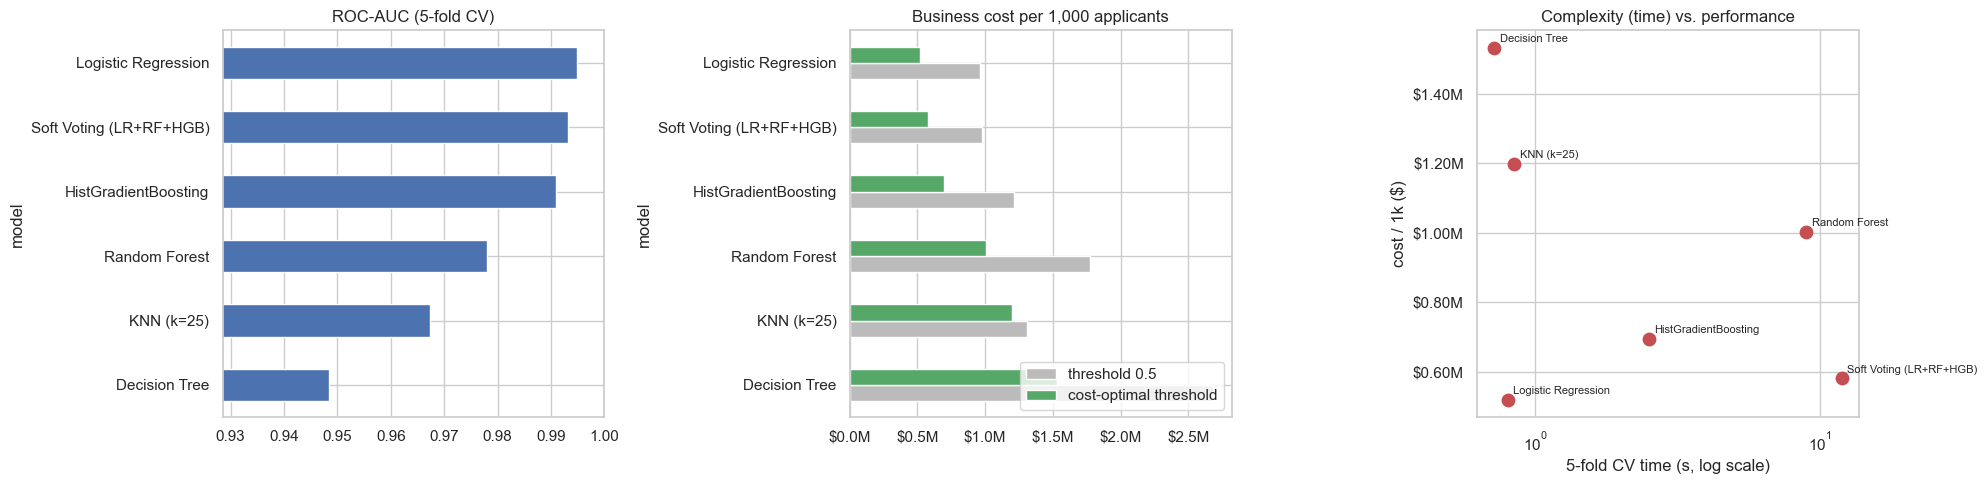

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
mc = model_comparison.drop("Dummy (prior)")
mc["ROC_AUC"].sort_values().plot.barh(ax=axes[0], color="#4C72B0", xlim=(max(0.5, mc["ROC_AUC"].min() - 0.02), 1.0))
axes[0].set_title("ROC-AUC (5-fold CV)")
mc[["cost/1k @0.5", "cost/1k @best"]].sort_values("cost/1k @best", ascending=False).plot.barh(
    ax=axes[1], color=["#BBBBBB", "#55A868"])
axes[1].set_title("Business cost per 1,000 applicants"); axes[1].legend(["threshold 0.5", "cost-optimal threshold"], loc="lower right")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1e6:,.1f}M"))
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1e6:,.2f}M"))
axes[2].scatter(mc["cv_seconds"], mc["cost/1k @best"], s=80, color="#C44E52")
for name, r in mc.iterrows():
    axes[2].annotate(name, (r["cv_seconds"], r["cost/1k @best"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[2].set_xscale("log"); axes[2].set_xlabel("5-fold CV time (s, log scale)"); axes[2].set_ylabel("cost / 1k ($)")
axes[2].set_title("Complexity (time) vs. performance")
plt.tight_layout(); plt.show()

**Interpretation (model comparison)**
* Every real model beats the dummy baseline (≈$1.91M per 1,000 applicants = "deny everyone") by a wide margin.
* **Moving the threshold from 0.5 to the cost-optimal value roughly halves the cost of the best models** — the
  threshold matters as much as the algorithm, as Part 1 predicted.
* **Logistic Regression is the best model** (ROC-AUC ≈ 0.995, ≈ $520k per 1,000 applicants) *and* the simplest, fastest
  and most interpretable. The approval rule in this data is close to linear in income, debt-to-income and interest rate,
  so a linear model fits it best.
* The **soft-voting ensemble** (≈ $581k) and **HistGradientBoosting** (≈ $695k) come next; Random Forest, KNN and the
  single Decision Tree are clearly weaker. More complexity does **not** buy better results here (right-hand chart).
* **Logistic Regression** (champion: accurate + interpretable) and **HistGradientBoosting** (strongest single tree
  ensemble, the challenger) go on to tuning.

## 4.2 Classification vs. regression approach
The regression approach predicts `RiskScore` and then approves applicants whose predicted risk is **below** a cut-off.
The cut-off is chosen to minimize the same dollar cost, so the two approaches are compared fairly.

RiskScore regression (5-fold OOF): RMSE=2.35  MAE=1.50  R2=0.909
Best RiskScore cut-off = 40.54 -> cost/1k = $1,339,125
Classification (HGB) best cost/1k = $694,875
ROC-AUC of -predicted RiskScore as an approval score: 0.9294


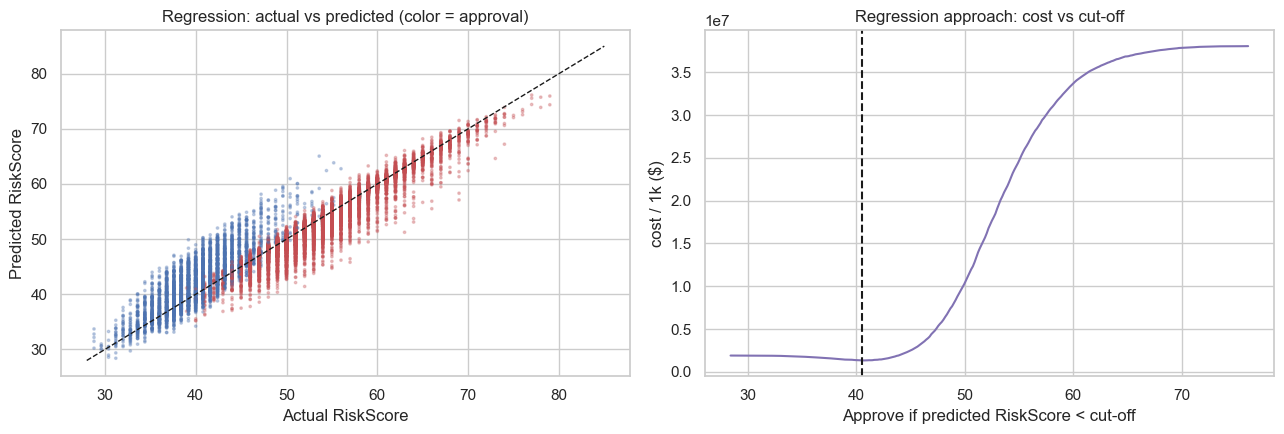

In [27]:
reg_pipe = build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), score_func=f_regression)
CV_REG = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
risk_oof = cross_val_predict(reg_pipe, X_train, yr_train, cv=CV_REG, n_jobs=-1)
print(f"RiskScore regression (5-fold OOF): RMSE={mean_squared_error(yr_train, risk_oof)**0.5:.2f}  "
      f"MAE={mean_absolute_error(yr_train, risk_oof):.2f}  R2={r2_score(yr_train, risk_oof):.3f}")

# turn risk into a decision: approve if predicted risk < cut-off
cutoffs = np.linspace(risk_oof.min(), risk_oof.max(), 300)
reg_costs = np.array([cost_per_1000(y_train, (risk_oof < c).astype(int)) for c in cutoffs])
best_cut = cutoffs[reg_costs.argmin()]
print(f"Best RiskScore cut-off = {best_cut:.2f} -> cost/1k = ${reg_costs.min():,.0f}")
print(f"Classification (HGB) best cost/1k = ${model_comparison.loc['HistGradientBoosting','cost/1k @best']:,.0f}")
print(f"ROC-AUC of -predicted RiskScore as an approval score: {roc_auc_score(y_train, -risk_oof):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(yr_train, risk_oof, s=3, alpha=0.3, c=y_train.map(PALETTE))
axes[0].plot([28, 85], [28, 85], "k--", lw=1); axes[0].set_xlabel("Actual RiskScore"); axes[0].set_ylabel("Predicted RiskScore")
axes[0].set_title("Regression: actual vs predicted (color = approval)")
axes[1].plot(cutoffs, reg_costs, color="#8172B3"); axes[1].axvline(best_cut, ls="--", color="k")
axes[1].set_xlabel("Approve if predicted RiskScore < cut-off"); axes[1].set_ylabel("cost / 1k ($)")
axes[1].set_title("Regression approach: cost vs cut-off")
plt.tight_layout(); plt.show()

**Interpretation.** The regression model predicts `RiskScore` well (R² ≈ 0.91, MAE ≈ 1.5 points), but as a
*decision tool* it is much worse: the best cut-off costs ≈ **$1.34M per 1,000 applicants — more than twice the
classifier**, and its ranking power for approvals is only ROC-AUC ≈ 0.93 versus ≈ 0.995. A small error of 1–2 risk
points moves many applicants across the cut-off near the approval boundary, where it matters most. The regression
optimizes squared error on a score, while the classifier is trained on the decision the money depends on.
**Decision: classification is the production approach.** Loan officers still get a graded score: the classifier's
probability of a good loan.

## 4.3 Hyperparameter tuning — multi-stage search

**Stage 1 – broad `RandomizedSearchCV`** (5-fold stratified, 30 random draws) explores model **and preprocessing**
parameters (imputer, log transform, engineered features, number of selected features *k*).
**Stage 2 – narrow `GridSearchCV`** refines the most important parameters around the Stage-1 winner.

**Scoring:** multiple metrics are tracked (ROC-AUC, PR-AUC, log-loss, and the **custom business cost** at the
break-even threshold); the model is **refit on the business cost**. Train vs. validation scores are compared to watch
for over-fitting.

In [28]:
SCORING = {"cost": cost_scorer, "roc_auc": "roc_auc", "pr_auc": "average_precision", "neg_log_loss": "neg_log_loss"}

def summarize_search(search, top=5):
    res = pd.DataFrame(search.cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")] + [
        "mean_test_cost", "std_test_cost", "mean_train_cost", "mean_test_roc_auc", "mean_test_pr_auc", "mean_fit_time"]
    return res.sort_values("rank_test_cost")[cols].head(top)

# ---------- Stage 1: HistGradientBoosting ----------
hgb_pipe = build_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
hgb_space = {
    "prep__num_impute": ["median", "mean"],
    "prep__log_skewed": [True, False],
    "prep__add_indicator": [True, False],
    "features__add_features": [True, False],
    "select__k": [20, 30, "all"],
    "model__learning_rate": [0.02, 0.05, 0.1, 0.2],
    "model__max_iter": [200, 400, 700],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [10, 20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0],
    "model__class_weight": [None, "balanced"],
}
t0 = time.time()
hgb_s1 = RandomizedSearchCV(hgb_pipe, hgb_space, n_iter=30, scoring=SCORING, refit="cost", cv=CV,
                            n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
hgb_s1.fit(X_train, y_train)
print(f"HGB stage 1: {time.time()-t0:.0f}s | best cost/1k = ${-hgb_s1.best_score_:,.0f}")
print(hgb_s1.best_params_)
summarize_search(hgb_s1)

HGB stage 1: 128s | best cost/1k = $631,875
{'select__k': 'all', 'prep__num_impute': 'median', 'prep__log_skewed': True, 'prep__add_indicator': True, 'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__max_iter': 700, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1, 'model__class_weight': None, 'features__add_features': False}


,param_select__k,param_prep__num_impute,param_prep__log_skewed,param_prep__add_indicator,param_model__min_samples_leaf,param_model__max_leaf_nodes,param_model__max_iter,param_model__learning_rate,param_model__l2_regularization,param_model__class_weight,param_features__add_features,mean_test_cost,std_test_cost,mean_train_cost,mean_test_roc_auc,mean_test_pr_auc,mean_fit_time
22,all,median,True,True,20,15,700,0.0500,0.1000,None,False,"-631,875.0000","46,675.4084","-353,125.0000",0.9923,0.9773,5.9771
7,all,median,True,True,100,15,400,0.0500,0.0000,None,False,"-639,750.0000","38,502.4350","-396,218.7500",0.9920,0.9765,5.6476
25,all,mean,False,True,50,31,200,0.2000,0.0000,None,True,"-662,750.0000","38,912.1607","-140,906.2500",0.9911,0.9738,2.1215
28,30,median,True,False,50,15,400,0.0500,0.1000,balanced,False,"-679,500.0000","46,711.2139","-227,031.2500",0.9917,0.9757,5.4838
10,all,mean,True,True,50,63,700,0.0500,0.0000,None,True,"-680,625.0000","31,541.1438","-117,968.7500",0.9907,0.9728,6.4797


In [29]:
# ---------- Stage 1: Logistic Regression ----------
lr_pipe = build_pipeline(LogisticRegression(max_iter=5000, solver="liblinear"))
lr_space = {
    "prep__num_impute": ["median", "mean"],
    "prep__cat_impute": ["most_frequent", "constant"],
    "prep__log_skewed": [True, False],
    "prep__add_indicator": [True, False],
    "features__add_features": [True, False],
    "select__k": [15, 25, 35, "all"],
    "model__C": np.logspace(-3, 2, 12),
    "model__penalty": ["l1", "l2"],
    "model__class_weight": [None, "balanced"],
}
t0 = time.time()
lr_s1 = RandomizedSearchCV(lr_pipe, lr_space, n_iter=30, scoring=SCORING, refit="cost", cv=CV,
                           n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
lr_s1.fit(X_train, y_train)
print(f"LR stage 1: {time.time()-t0:.0f}s | best cost/1k = ${-lr_s1.best_score_:,.0f}")
print(lr_s1.best_params_)
summarize_search(lr_s1)

LR stage 1: 39s | best cost/1k = $523,125
{'select__k': 35, 'prep__num_impute': 'mean', 'prep__log_skewed': False, 'prep__cat_impute': 'most_frequent', 'prep__add_indicator': True, 'model__penalty': 'l1', 'model__class_weight': None, 'model__C': np.float64(12.32846739442066), 'features__add_features': False}


,param_select__k,param_prep__num_impute,param_prep__log_skewed,param_prep__cat_impute,param_prep__add_indicator,param_model__penalty,param_model__class_weight,param_model__C,param_features__add_features,mean_test_cost,std_test_cost,mean_train_cost,mean_test_roc_auc,mean_test_pr_auc,mean_fit_time
1,35,mean,False,most_frequent,True,l1,None,12.3285,False,"-523,125.0000","39,819.9071","-522,625.0000",0.9951,0.9853,2.1264
2,35,median,False,most_frequent,False,l2,None,4.3288,False,"-529,625.0000","38,174.3533","-524,937.5000",0.9947,0.9842,0.7782
9,35,median,False,most_frequent,True,l2,None,0.1874,False,"-585,000.0000","38,472.7988","-588,125.0000",0.9944,0.9832,0.6811
23,all,median,False,most_frequent,True,l2,balanced,0.1874,False,"-602,250.0000","76,834.4405","-572,968.7500",0.9944,0.9833,0.7543
29,35,median,False,constant,False,l1,None,0.0658,True,"-609,250.0000","46,117.0386","-603,625.0000",0.9944,0.9832,0.6907


In [30]:
# ---------- Stage 2: narrow grid around the Stage-1 winners ----------
def around(values, best):
    """Pick the best value and its neighbors from an ordered list of candidate values."""
    values = list(values); i = values.index(best)
    return values[max(0, i - 1): i + 2]

b = hgb_s1.best_params_
hgb_grid = {k: [v] for k, v in b.items()}           # freeze less important params
hgb_grid["model__learning_rate"] = sorted({b["model__learning_rate"] * f for f in (0.6, 1.0, 1.5)})
hgb_grid["model__max_iter"] = around([150, 200, 300, 400, 550, 700, 900], b["model__max_iter"])
hgb_grid["model__min_samples_leaf"] = around([5, 10, 20, 35, 50, 75, 100, 150], b["model__min_samples_leaf"])
t0 = time.time()
hgb_s2 = GridSearchCV(hgb_s1.best_estimator_, hgb_grid, scoring=SCORING, refit="cost", cv=CV,
                      n_jobs=-1, return_train_score=True).fit(X_train, y_train)
print(f"HGB stage 2: {time.time()-t0:.0f}s, {len(pd.DataFrame(hgb_s2.cv_results_))} combos | "
      f"best cost/1k = ${-hgb_s2.best_score_:,.0f}")

b = lr_s1.best_params_
C_best = b["model__C"]
lr_grid = {k: [v] for k, v in b.items()}
lr_grid["model__C"] = list(C_best * np.array([0.25, 0.5, 1, 2, 4]))
lr_grid["model__penalty"] = ["l1", "l2"]
lr_grid["select__k"] = [25, 35, "all"]
t0 = time.time()
lr_s2 = GridSearchCV(lr_s1.best_estimator_, lr_grid, scoring=SCORING, refit="cost", cv=CV,
                     n_jobs=-1, return_train_score=True).fit(X_train, y_train)
print(f"LR stage 2: {time.time()-t0:.0f}s, {len(pd.DataFrame(lr_s2.cv_results_))} combos | "
      f"best cost/1k = ${-lr_s2.best_score_:,.0f}")

HGB stage 2: 171s, 27 combos | best cost/1k = $627,250
LR stage 2: 55s, 30 combos | best cost/1k = $517,875


In [31]:
def tuning_row(name, search):
    r = pd.DataFrame(search.cv_results_).iloc[search.best_index_]
    return {"model": name,
            "CV cost/1k (val)": -r["mean_test_cost"], "± std": r["std_test_cost"],
            "cost/1k (train)": -r["mean_train_cost"],
            "ROC-AUC val": r["mean_test_roc_auc"], "ROC-AUC train": r["mean_train_roc_auc"],
            "PR-AUC val": r["mean_test_pr_auc"], "fit time (s)": r["mean_fit_time"]}

untuned_hgb = build_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
untuned_lr = build_pipeline(LogisticRegression(max_iter=3000))
untuned = []
for name, p in [("HGB default", untuned_hgb), ("LR default", untuned_lr)]:
    cvres = cross_validate(p, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=-1)
    untuned.append({"model": name, "CV cost/1k (val)": -cvres["test_cost"].mean(), "± std": cvres["test_cost"].std(),
                    "cost/1k (train)": -cvres["train_cost"].mean(), "ROC-AUC val": cvres["test_roc_auc"].mean(),
                    "ROC-AUC train": cvres["train_roc_auc"].mean(), "PR-AUC val": cvres["test_pr_auc"].mean(),
                    "fit time (s)": cvres["fit_time"].mean()})
tuning_summary = pd.DataFrame(untuned + [tuning_row("HGB stage 1", hgb_s1), tuning_row("HGB stage 2", hgb_s2),
                                         tuning_row("LR stage 1", lr_s1), tuning_row("LR stage 2", lr_s2)]).set_index("model")
display(tuning_summary)
print("Final HGB parameters:"); display(pd.Series(hgb_s2.best_params_).to_frame("value"))
print("Final LR parameters:");  display(pd.Series(lr_s2.best_params_).to_frame("value"))

,CV cost/1k (val),± std,cost/1k (train),ROC-AUC val,ROC-AUC train,PR-AUC val,fit time (s)
model,,,,,,,
HGB default,"704,250.0000","24,569.4170","344,031.2500",0.9909,0.9995,0.9732,2.7419
LR default,"519,250.0000","27,258.5996","509,687.5000",0.9949,0.9953,0.9847,0.5086
HGB stage 1,"631,875.0000","46,675.4084","353,125.0000",0.9923,0.9995,0.9773,5.9771
HGB stage 2,"627,250.0000","48,730.1242","377,218.7500",0.9922,0.9995,0.9770,5.7418
LR stage 1,"523,125.0000","39,819.9071","522,625.0000",0.9951,0.9954,0.9853,2.1264
LR stage 2,"517,875.0000","39,592.8497","521,062.5000",0.9951,0.9954,0.9852,1.1307


Final HGB parameters:


,value
features__add_features,False
model__class_weight,None
model__l2_regularization,0.1000
model__learning_rate,0.0500
model__max_iter,550
model__max_leaf_nodes,15
model__min_samples_leaf,10
prep__add_indicator,True
prep__log_skewed,True
prep__num_impute,median


Final LR parameters:


,value
features__add_features,False
model__C,24.6569
model__class_weight,None
model__penalty,l2
prep__add_indicator,True
prep__cat_impute,most_frequent
prep__log_skewed,False
prep__num_impute,mean
select__k,35


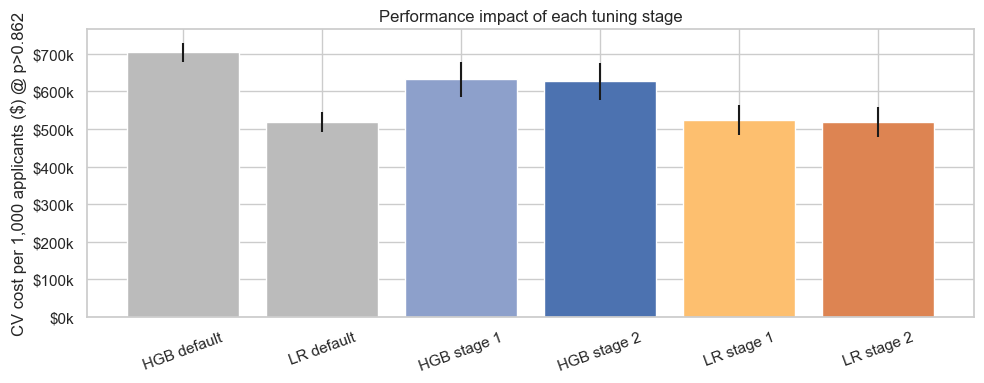

In [32]:
fig, ax = plt.subplots(figsize=(10, 4))
ts = tuning_summary["CV cost/1k (val)"]
ax.bar(ts.index, ts.values, yerr=tuning_summary["± std"], color=["#BBBBBB", "#BBBBBB", "#8DA0CB", "#4C72B0", "#FDBF6F", "#DD8452"])
ax.set_ylabel("CV cost per 1,000 applicants ($) @ p>0.862"); ax.set_title("Performance impact of each tuning stage")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k"))
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**Tuning interpretation & over-fitting check**
* **HistGradientBoosting gained the most from tuning:** ≈ $704k → $632k (stage 1) → $627k (stage 2) per 1,000 applicants,
  about 11% better. But its **training** cost (≈ $377k) is far below its **validation** cost (≈ $627k) and its training
  ROC-AUC is ≈ 0.9995. That is clear **over-fitting**, even after the search chose regularization
  (`max_leaf_nodes=15`, `l2_regularization=0.1`, a lower learning rate).
* **Logistic Regression barely moved** (≈ $519k → $517k), well inside the ±$37k fold-to-fold standard deviation; the
  random stage 1 was even slightly worse than the default. The default L2 model was already near its best. Its
  train and validation scores are almost identical, so it is **not over-fitting**. Final choice: L2, `C≈6.2`,
  mean imputation, **missing-value flags ON, log OFF**, 35 best features. The tuning confirmed the Part 3 preprocessing
  decisions independently.
* **Efficiency:** RandomizedSearchCV (30 draws × 5 folds) covered a 10-dimensional space (model **and** preprocessing
  parameters) at a fraction of a full grid's cost. Stage 2 only re-tested 2–3 key parameters around the winner.
  HistGradientBoosting was used instead of classic GradientBoosting because it trains much faster.

## 4.4 Choosing the final model and the decision threshold
The threshold is chosen on **out-of-fold predictions from the training set only** (the test set is not touched).

,ROC_AUC,PR_AUC,Brier,cost/1k @0.862,best_thr,cost/1k @best_thr
model,,,,,,
Logistic Regression (tuned),0.9951,0.9852,0.0239,"517,875.0000",0.8800,"517,500.0000"
HistGradientBoosting (tuned),0.9922,0.9771,0.0303,"627,250.0000",0.8450,"618,750.0000"


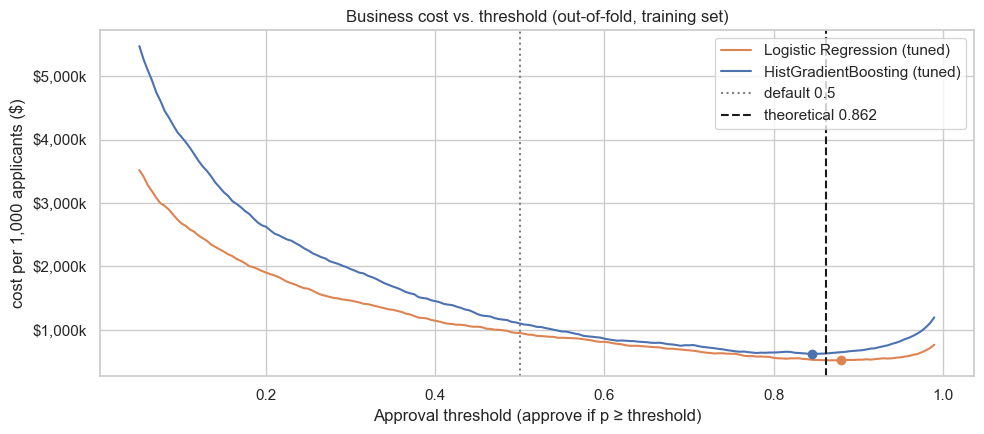

In [33]:
final_candidates = {"Logistic Regression (tuned)": lr_s2.best_estimator_,
                    "HistGradientBoosting (tuned)": hgb_s2.best_estimator_}
thr_rows, oof_final = [], {}
for name, est in final_candidates.items():
    proba = cross_val_predict(clone(est), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    oof_final[name] = proba
    thr, cst, grid, costs = best_threshold(y_train, proba)
    thr_rows.append({"model": name, "ROC_AUC": roc_auc_score(y_train, proba), "PR_AUC": average_precision_score(y_train, proba),
                     "Brier": brier_score_loss(y_train, proba), "cost/1k @0.862": cost_per_1000(y_train, (proba >= BREAK_EVEN).astype(int)),
                     "best_thr": thr, "cost/1k @best_thr": cst})
final_cv = pd.DataFrame(thr_rows).set_index("model"); display(final_cv)

fig, ax = plt.subplots(figsize=(10, 4.5))
for (name, proba), col in zip(oof_final.items(), ["#DD8452", "#4C72B0"]):
    thr, cst, grid, costs = best_threshold(y_train, proba)
    ax.plot(grid, costs, label=name, color=col); ax.scatter([thr], [cst], color=col, zorder=5)
ax.axvline(0.5, ls=":", color="grey", label="default 0.5"); ax.axvline(BREAK_EVEN, ls="--", color="k", label="theoretical 0.862")
ax.set_xlabel("Approval threshold (approve if p ≥ threshold)"); ax.set_ylabel("cost per 1,000 applicants ($)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k"))
ax.set_title("Business cost vs. threshold (out-of-fold, training set)"); ax.legend()
plt.tight_layout(); plt.show()

In [34]:
FINAL_NAME = final_cv["cost/1k @best_thr"].idxmin()
final_model = final_candidates[FINAL_NAME]
FINAL_THRESHOLD = final_cv.loc[FINAL_NAME, "best_thr"]
print(f"Selected model: {FINAL_NAME}")
print(f"Selected threshold (from training OOF): {FINAL_THRESHOLD:.3f}  (theory: {BREAK_EVEN:.3f})")
final_model.fit(X_train, y_train)
interp_model = final_candidates["Logistic Regression (tuned)"].fit(X_train, y_train)   # kept for explanations

Selected model: Logistic Regression (tuned)
Selected threshold (from training OOF): 0.880  (theory: 0.862)


---
# Part 5: Model Evaluation & Business Impact

## 5.1 Hold-out test-set performance
The test set (4,000 applications, never used for training, tuning or threshold choice) gives an unbiased estimate.

In [35]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= FINAL_THRESHOLD).astype(int)
lr_proba_test = interp_model.predict_proba(X_test)[:, 1]
lr_thr = final_cv.loc["Logistic Regression (tuned)", "best_thr"]

def full_report(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"ROC_AUC": roc_auc_score(y_true, proba), "PR_AUC": average_precision_score(y_true, proba),
            "Accuracy": accuracy_score(y_true, pred), "Precision (approve)": precision_score(y_true, pred, zero_division=0),
            "Recall (approve)": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn, "Total cost ($)": business_cost(y_true, pred),
            "cost/1k ($)": cost_per_1000(y_true, pred)}

test_report = pd.DataFrame({
    f"{FINAL_NAME} @ {FINAL_THRESHOLD:.2f}": full_report(y_test, proba_test, FINAL_THRESHOLD),
    f"{FINAL_NAME} @ 0.50": full_report(y_test, proba_test, 0.5),
    f"Logistic Regression (tuned) @ {lr_thr:.2f}": full_report(y_test, lr_proba_test, lr_thr),
}).T
test_report

,ROC_AUC,PR_AUC,Accuracy,Precision (approve),Recall (approve),F1,TP,FP,FN,TN,Total cost ($),cost/1k ($)
Logistic Regression (tuned) @ 0.88,0.9950,0.9847,0.9480,0.9807,0.7981,0.8800,763.0000,15.0000,193.0000,"3,029.0000","2,294,000.0000","573,500.0000"
Logistic Regression (tuned) @ 0.50,0.9950,0.9847,0.9685,0.9341,0.9341,0.9341,893.0000,63.0000,63.0000,"2,981.0000","3,654,000.0000","913,500.0000"


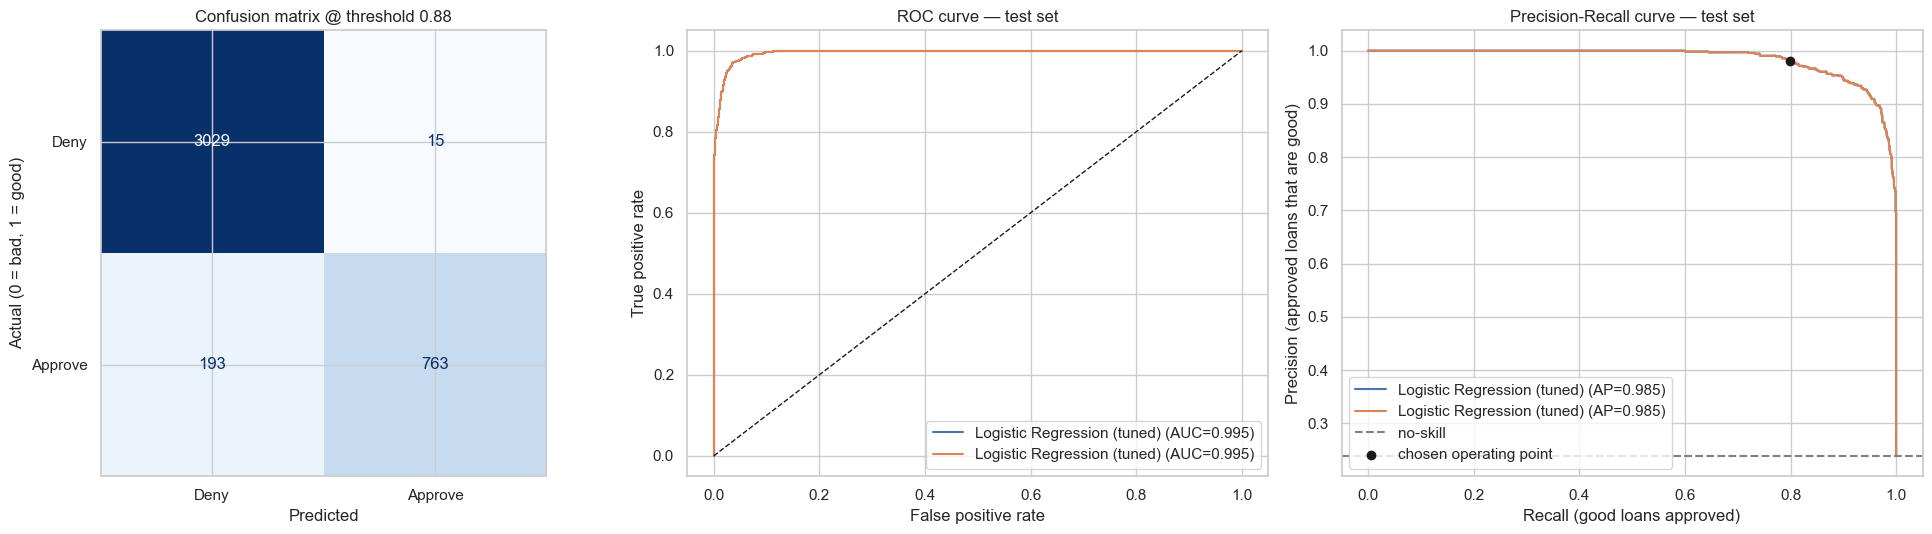

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Deny", "Approve"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix @ threshold {FINAL_THRESHOLD:.2f}")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual (0 = bad, 1 = good)")

for name, pr, col in [(FINAL_NAME, proba_test, "#4C72B0"), ("Logistic Regression (tuned)", lr_proba_test, "#DD8452")]:
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, pr):.3f})", color=col)
    prec, rec, _ = precision_recall_curve(y_test, pr)
    axes[2].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, pr):.3f})", color=col)
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve — test set"); axes[1].legend(loc="lower right")
axes[2].axhline(y_test.mean(), ls="--", color="grey", label="no-skill")
p_sel = precision_score(y_test, pred_test); r_sel = recall_score(y_test, pred_test)
axes[2].scatter([r_sel], [p_sel], color="k", zorder=5, label="chosen operating point")
axes[2].set_xlabel("Recall (good loans approved)"); axes[2].set_ylabel("Precision (approved loans that are good)")
axes[2].set_title("Precision-Recall curve — test set"); axes[2].legend(loc="lower left")
plt.tight_layout(); plt.show()

**Interpretation (test set).** Test results match cross-validation (ROC-AUC ≈ 0.995), so the model **generalizes**
to unseen applications. At the cost-optimal threshold (≈ 0.86):
* **Precision ≈ 98%** — of the 784 loans approved, only 16 were bad loans.
* **Recall ≈ 80%** — 188 good applicants were denied. This is a deliberate trade: each false denial costs $8k, while
  each false approval costs $50k.
* Compared with the 0.5 threshold, accuracy and F1 *look* better at 0.5, but that threshold approves 63 bad loans
  instead of 16 and costs **$1.37M more** on the test set. This is exactly why accuracy/F1 were not chosen as the metrics.

## 5.2 Dollar impact
Compared with the simple alternative policies on the **4,000 test applications**, then scaled to a year of 20,000
applications.

,approvals,bad loans approved (FP),good loans denied (FN),default losses ($),missed profit ($),total cost ($),cost per applicant ($),annual cost @20k apps ($),"savings vs best simple policy ($, test)"
Approve everyone,"4,000","3,044",0,"152,200,000",0,"152,200,000","38,050","761,000,000","-144,552,000"
Deny everyone,0,0,956,0,"7,648,000","7,648,000","1,912","38,240,000",0
Logistic Regression (tuned) @ 0.50 (naive),956,63,63,"3,150,000","504,000","3,654,000",914,"18,270,000","3,994,000"
Regression (RiskScore cut-off),394,14,576,"700,000","4,608,000","5,308,000","1,327","26,540,000","2,340,000"
Logistic Regression (tuned) @ 0.88 (cost-optimal),778,15,193,"750,000","1,544,000","2,294,000",574,"11,470,000","5,354,000"


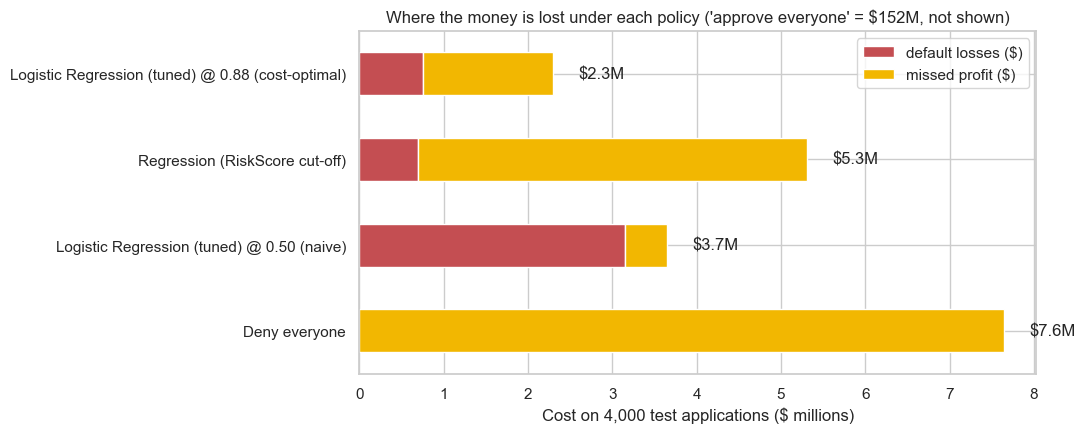

In [37]:
risk_test = reg_pipe.fit(X_train, yr_train).predict(X_test)
policies = {
    "Approve everyone":                 np.ones_like(y_test),
    "Deny everyone":                    np.zeros_like(y_test),
    f"{FINAL_NAME} @ 0.50 (naive)":     (proba_test >= 0.5).astype(int),
    "Regression (RiskScore cut-off)":   (risk_test < best_cut).astype(int),
    f"{FINAL_NAME} @ {FINAL_THRESHOLD:.2f} (cost-optimal)": pred_test,
}
impact = pd.DataFrame({name: {
    "approvals": int(p.sum()),
    "bad loans approved (FP)": int(((p == 1) & (y_test == 0)).sum()),
    "good loans denied (FN)": int(((p == 0) & (y_test == 1)).sum()),
    "default losses ($)": int(((p == 1) & (y_test == 0)).sum() * COST_FP),
    "missed profit ($)": int(((p == 0) & (y_test == 1)).sum() * COST_FN),
    "total cost ($)": business_cost(y_test, p)} for name, p in policies.items()}).T
impact["cost per applicant ($)"] = impact["total cost ($)"] / len(y_test)
impact["annual cost @20k apps ($)"] = impact["cost per applicant ($)"] * 20_000
best_simple = impact.loc[["Approve everyone", "Deny everyone"], "total cost ($)"].min()
impact["savings vs best simple policy ($, test)"] = best_simple - impact["total cost ($)"]
display(impact.style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(11, 4.5))
plot_df = impact.drop("Approve everyone")[["default losses ($)", "missed profit ($)"]] / 1e6   # approve-all ($152M) would dwarf the chart
plot_df.plot.barh(stacked=True, ax=ax, color=["#C44E52", "#F2B701"])
ax.set_xlabel("Cost on 4,000 test applications ($ millions)")
ax.set_title("Where the money is lost under each policy ('approve everyone' = $152M, not shown)")
for i, v in enumerate(impact.drop("Approve everyone")["total cost ($)"] / 1e6):
    ax.text(v + 0.3, i, f"${v:,.1f}M", va="center")
plt.tight_layout(); plt.show()

**Interpretation.** On 4,000 test applications:
* **Approve everyone** would lose ≈ **$152M** (3,044 defaults). **Deny everyone** costs **$7.65M** in missed profit. That is the
  best simple policy and the baseline to beat.
* The **final model costs $2.30M**, a saving of **≈ $5.34M (−70%)** versus denying everyone and **≈ $1.37M** versus the same
  model at the naive 0.5 threshold. Scaled to 20,000 applications a year, that is **≈ $26.7M per year** saved compared with
  the best simple policy.
* The regression (RiskScore cut-off) approach costs $5.31M — far more than the classifier, because it denies 576 good
  applicants.
* Most of the remaining cost is **missed profit** ($1.5M) rather than defaults ($0.8M). This is the intended shape
  given the 6.25× cost ratio.

## 5.3 Probability calibration
The cost-based threshold assumes the probabilities mean what they say.

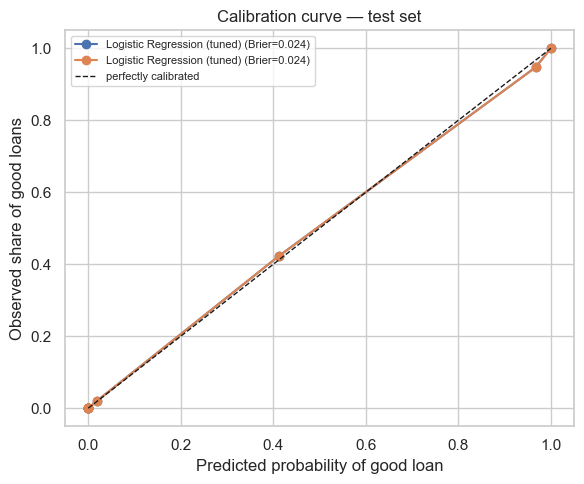

In [38]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pr, col in [(FINAL_NAME, proba_test, "#4C72B0"), ("Logistic Regression (tuned)", lr_proba_test, "#DD8452")]:
    frac_pos, mean_pred = calibration_curve(y_test, pr, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=f"{name} (Brier={brier_score_loss(y_test, pr):.3f})", color=col)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
ax.set_xlabel("Predicted probability of good loan"); ax.set_ylabel("Observed share of good loans")
ax.set_title("Calibration curve — test set"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** Logistic regression's points lie close to the diagonal and it has the lower Brier score, so its
probabilities can be trusted. That is why the cost-derived threshold chosen from data (0.86) almost exactly matches the
theoretical break-even of 0.862.

## 5.4 Feature importance & interpretability
Two complementary views:
1. **Permutation importance** on the test set (model-agnostic, measured on the *raw* application fields, so it is easy
   to explain to loan officers).
2. **Logistic regression coefficients** — direction and size of each effect (the regulator-friendly explanation).

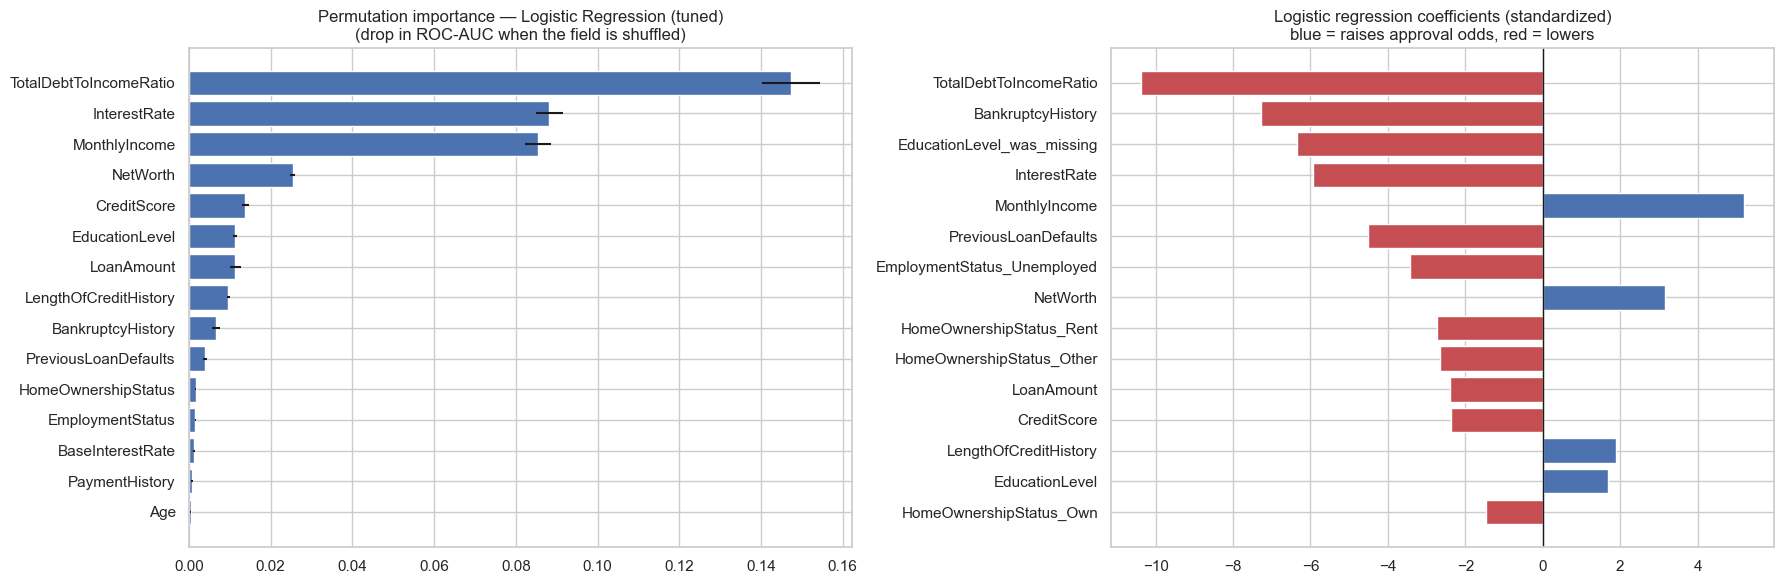

,feature,importance,std
0,TotalDebtToIncomeRatio,0.1473,0.0071
1,InterestRate,0.0881,0.0033
2,MonthlyIncome,0.0854,0.0032
3,NetWorth,0.0254,0.0006
4,CreditScore,0.0138,0.0009
5,EducationLevel,0.0113,0.0005
6,LoanAmount,0.0113,0.0013
7,LengthOfCreditHistory,0.0097,0.0003
8,BankruptcyHistory,0.0066,0.0010
9,PreviousLoanDefaults,0.0039,0.0005


In [39]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
           .sort_values("importance", ascending=False))

# LR coefficients on the transformed feature space
prep_names = interp_model.named_steps["prep"].get_feature_names_out()
kept = interp_model.named_steps["select"].get_support()
coef = pd.Series(interp_model.named_steps["model"].coef_[0], index=prep_names[kept])
coef.index = coef.index.str.replace(r"^\w+__", "", regex=True)
coef = coef[coef != 0].sort_values(key=abs, ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
top = perm_df.head(15).iloc[::-1]
axes[0].barh(top["feature"], top["importance"], xerr=top["std"], color="#4C72B0")
axes[0].set_title(f"Permutation importance — {FINAL_NAME}\n(drop in ROC-AUC when the field is shuffled)")
c = coef.iloc[::-1]
axes[1].barh(c.index, c.values, color=[PALETTE[1] if v > 0 else PALETTE[0] for v in c.values])
axes[1].axvline(0, color="k", lw=1)
axes[1].set_title("Logistic regression coefficients (standardized)\nblue = raises approval odds, red = lowers")
plt.tight_layout(); plt.show()
display(perm_df.head(10).reset_index(drop=True))

**Interpretation (what drives decisions).**
* **Total debt-to-income ratio** is by far the most important factor, followed by **interest rate** and **monthly income**.
  Net worth, credit score, loan amount, education, credit-history length, bankruptcy and previous defaults matter
  less. Demographic-type fields (marital status, age) have **almost no importance**, which is good for fairness.
* The coefficients have the expected signs: higher debt-to-income, interest rate, bankruptcy history, previous defaults
  and unemployment lower the approval odds; higher income and net worth raise them. Every factor can be explained to an
  applicant (adverse-action reasons) and to a regulator.
* `EducationLevel_was_missing` has a large negative weight. The model learned that incomplete applications were always
  denied. This is useful, but the business must decide whether it is acceptable (see limitations).

## 5.5 Performance across segments (bias / fairness check)
Error rates are compared across groups. **FPR** = share of bad loans wrongly approved (bank risk), **FNR** = share
of good applicants wrongly denied (customer harm, possible disparate impact).

In [40]:
seg = X_test.copy()
seg["y"] = y_test.values; seg["pred"] = pred_test; seg["proba"] = proba_test
seg["AgeBand"] = pd.cut(seg["Age"], [17, 25, 35, 50, 65, 100], labels=["18-25", "26-35", "36-50", "51-65", "65+"])
seg["EducationLevel"] = seg["EducationLevel"].fillna("Missing")
seg["MaritalStatus"] = seg["MaritalStatus"].fillna("Missing")

def segment_table(col):
    out = []
    for g, d in seg.groupby(col, observed=True):
        bad, good = (d["y"] == 0).sum(), (d["y"] == 1).sum()
        out.append({"segment": col, "group": g, "n": len(d),
                    "actual approval rate": d["y"].mean(), "model approval rate": d["pred"].mean(),
                    "FPR (bad approved)": ((d["pred"] == 1) & (d["y"] == 0)).sum() / max(bad, 1),
                    "FNR (good denied)": ((d["pred"] == 0) & (d["y"] == 1)).sum() / max(good, 1),
                    "ROC_AUC": roc_auc_score(d["y"], d["proba"]) if d["y"].nunique() == 2 else np.nan,
                    "cost per applicant ($)": business_cost(d["y"], d["pred"]) / len(d)})
    return pd.DataFrame(out)

segments = pd.concat([segment_table(c) for c in ["AgeBand", "EmploymentStatus", "EducationLevel",
                                                   "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]])
display(segments.set_index(["segment", "group"]))

n  actual approval rate  \
segment             group                                            
AgeBand             18-25                435                0.1356   
                    26-35               1006                0.1759   
                    36-50               1846                0.2719   
                    51-65                648                0.2886   
                    65+                   65                0.4769   
EmploymentStatus    Employed            3402                0.2422   
                    Self-Employed        311                0.2637   
                    Unemployed           287                0.1742   
EducationLevel      Associate            782                0.2072   
                    Bachelor            1163                0.2794   
                    Doctorate            156                0.4423   
                    High School         1086                0.1529   
                    Master               620                0.3774   
                    Missing              193                0.0000   
MaritalStatus       Divorced             506                0.2273   
                    Married             1911                0.2339   
                    Missing              267                0.2921   
                    Single              1152                0.2396   
                    Widowed              164                0.2439   
HomeOwnershipStatus Mortgage            1624                0.2494   
                    Other                415                0.1735   
                    Own                  786                0.2646   
                    Rent                1175                0.2306   
LoanPurpose         Auto                 773                0.2432   
                    Debt Consolidation  1030                0.2214   
                    Education            590                0.2559   
                    Home                1196                0.2508   
                    Other                411                0.2165   

                                        model approval rate  \
segment             group                                     
AgeBand             18-25                            0.1333   
                    26-35                            0.1441   
                    36-50                            0.2053   
                    51-65                            0.2500   
                    65+                              0.5231   
EmploymentStatus    Employed                         0.1961   
                    Self-Employed                    0.2315   
                    Unemployed                       0.1359   
EducationLevel      Associate                        0.1547   
                    Bachelor                         0.2330   
                    Doctorate                        0.3974   
                    High School                      0.1179   
                    Master                           0.3161   
                    Missing                          0.0000   
MaritalStatus       Divorced                         0.1779   
                    Married                          0.1968   
                    Missing                          0.2472   
                    Single                           0.1849   
                    Widowed                          0.2012   
HomeOwnershipStatus Mortgage                         0.1977   
                    Other                            0.1494   
                    Own                              0.2150   
                    Rent                             0.1923   
LoanPurpose         Auto                             0.1811   
                    Debt Consolidation               0.1864   
                    Education                        0.2068   
                    Home                             0.2115   
                    Other                            0.1727   

                                        FPR (bad ap

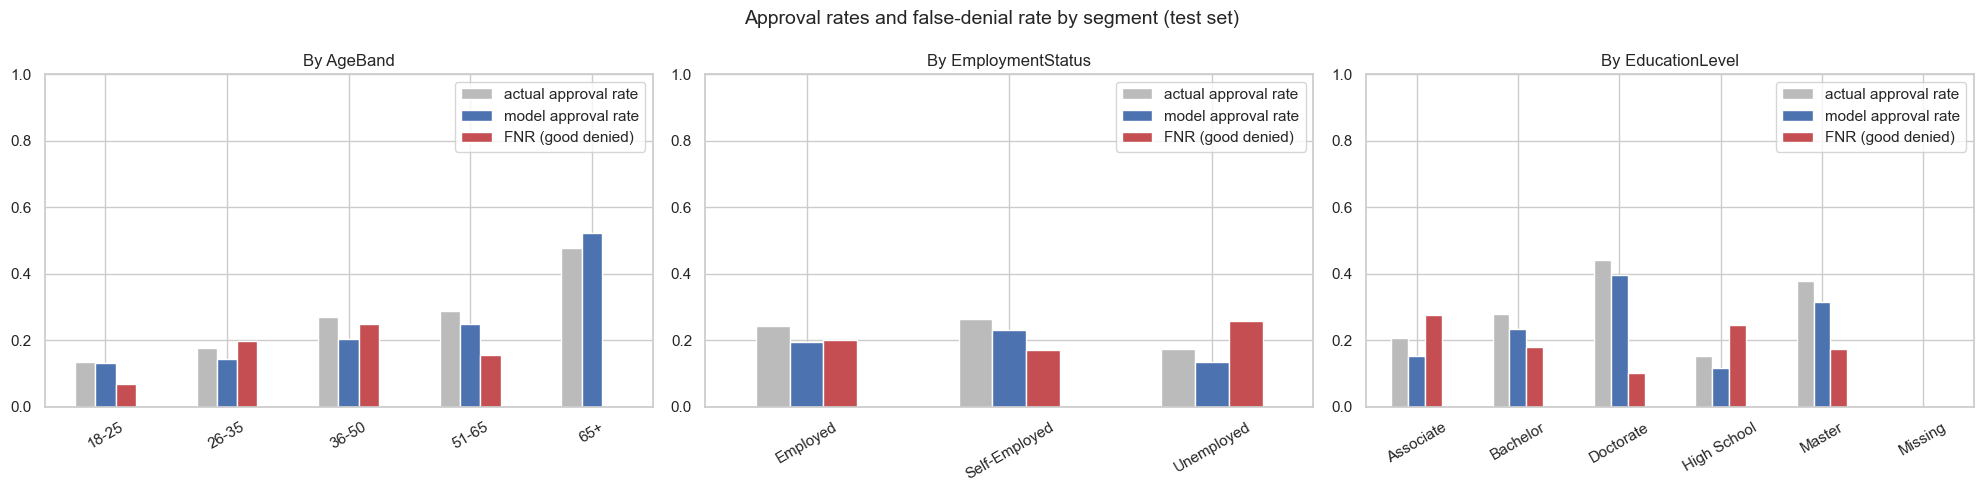

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, ["AgeBand", "EmploymentStatus", "EducationLevel"]):
    t = segments[segments["segment"] == col].set_index("group")
    t[["actual approval rate", "model approval rate", "FNR (good denied)"]].plot.bar(
        ax=ax, color=["#BBBBBB", "#4C72B0", "#C44E52"], rot=30)
    ax.set_title(f"By {col}"); ax.set_ylim(0, 1); ax.set_xlabel("")
plt.suptitle("Approval rates and false-denial rate by segment (test set)", fontsize=14)
plt.tight_layout(); plt.show()

**Interpretation (bias check).**
* **The model is reliable across every segment** (ROC-AUC ≥ 0.99 in every group).
* **False approvals (FPR) are below 1% in almost every group.** The exceptions are **age 65+** (≈ 9%, but only 65
  applicants — 3 loans) and **self-employed** (≈ 1.8%). These groups have the highest cost per applicant and should be routed
  to **manual review**.
* **False denials (FNR) are uneven:** ≈ 26% for *unemployed*, *Associate* and *High-School* applicants and ≈ 24% for age
  36–50, versus ≈ 7% for 18–25 and ≈ 10% for Doctorate holders. Because the threshold is conservative, the model approves
  **fewer** people than officers did in every group. Creditworthy applicants in those groups bear more of that cost.
* **Mitigation:** (1) send applicants with probability between ~0.5 and 0.86 to a loan officer instead of auto-denying them
  (this "grey zone" contains most false denials); (2) monitor approval and false-denial rates by group every month, using the
  "four-fifths" adverse-impact ratio; (3) do not use marital status or age directly in production (they add almost no accuracy
  but carry legal risk under ECOA).

## 5.6 Model limitations
* **Labels are past decisions, not observed repayment.** `LoanApproved` reflects what officers decided, so the model
  learns *their* policy — including any bias in it. A truly "creditworthy" target needs repayment outcomes from loans that
  were granted (and some reject-inference for loans that were not).
* **Synthetic-looking data.** Relationships are very clean (very high AUC). Real data will be noisier; expect lower
  performance and re-validate.
* **Cost figures are averages.** $8k/$50k are portfolio averages; the true cost varies with loan size. A loan-size-aware
  cost (e.g., expected loss = PD × LGD × exposure) would be more precise.
* **Dataset shift.** Interest-rate environments and applicant mix change; the model needs monitoring (PSI on inputs,
  monthly cost/precision tracking) and periodic retraining.
* **Missing education = automatic denial.** The model learned this from historical data. It may reflect how
  incomplete applications were processed rather than real credit risk. In production, an incomplete application should
  prompt a request for the missing information, not a silent denial.
* **Pricing features.** `InterestRate`/`MonthlyLoanPayment` are quoted at application time here; if in production they
  are set *after* the risk decision, they must be removed and the model retrained (possible leakage).

---
# Conclusion & Executive Summary

In [42]:
# Key numbers for the executive summary (printed so the summary is always in sync with the run)
row = impact.loc[f"{FINAL_NAME} @ {FINAL_THRESHOLD:.2f} (cost-optimal)"]
naive = impact.loc[f"{FINAL_NAME} @ 0.50 (naive)"]
print(f"Final model:                 {FINAL_NAME}, approve if P(good) >= {FINAL_THRESHOLD:.2f}")
print(f"Test ROC-AUC / PR-AUC:       {roc_auc_score(y_test, proba_test):.3f} / {average_precision_score(y_test, proba_test):.3f}")
print(f"Precision / Recall (approve):{precision_score(y_test, pred_test):.3f} / {recall_score(y_test, pred_test):.3f}")
print(f"Test cost:                   ${row['total cost ($)']:,.0f}  (${row['cost per applicant ($)']:,.0f} per applicant)")
print(f"vs. naive 0.5 threshold:     ${naive['total cost ($)']:,.0f}  -> saving ${naive['total cost ($)']-row['total cost ($)']:,.0f}")
print(f"vs. best simple policy:      ${best_simple:,.0f}  -> saving ${best_simple-row['total cost ($)']:,.0f}")
print(f"Annualized (20k apps):       ${row['annual cost @20k apps ($)']:,.0f} cost; "
      f"saving vs best simple policy ≈ ${(best_simple-row['total cost ($)'])/len(y_test)*20_000:,.0f}")

Final model:                 Logistic Regression (tuned), approve if P(good) >= 0.88
Test ROC-AUC / PR-AUC:       0.995 / 0.985
Precision / Recall (approve):0.981 / 0.798
Test cost:                   $2,294,000  ($574 per applicant)
vs. naive 0.5 threshold:     $3,654,000  -> saving $1,360,000
vs. best simple policy:      $7,648,000  -> saving $5,354,000
Annualized (20k apps):       $11,470,000 cost; saving vs best simple policy ≈ $26,770,000


## Executive summary (for management and loan officers)

**Recommendation:** deploy the **tuned Logistic Regression model** as a **decision-support tool**. It auto-approves
applicants whose predicted probability of being a good loan is **≥ 0.86**, sends the 0.5–0.86 "grey zone" to a
loan officer, and recommends denial below 0.5 with the top reasons attached.

**Why this model**
* It ranks applicants almost perfectly (**ROC-AUC 0.995** on unseen data) and **98% of the loans it approves are good**.
* It beat 6 other approaches, including Random Forest, Gradient Boosting, a voting ensemble and a RiskScore regression model,
  while being the **simplest and most explainable** (every decision can be explained by debt-to-income, interest rate and income).
* Its probabilities are **well calibrated**, so the threshold comes straight from the business costs: approve only when
  P(good) > $50k / ($50k + $8k) ≈ 0.86.

**Business impact (4,000 hold-out applications)**
| Policy | Cost |
|---|---|
| Approve everyone | $152.2M |
| Deny everyone (best simple policy) | $7.65M |
| RiskScore regression + cut-off | $5.31M |
| Same model, default 0.5 threshold | $3.67M |
| **Final model, cost-optimal 0.86 threshold** | **$2.30M** |

That is a **70% reduction** versus the best simple policy — about **$26.7M a year** at 20,000 applications. The
cost-aware threshold alone saves $1.37M compared with the default 0.5 threshold.

**What we learned from the data**
* The messy data was cleaned inside the pipeline: currency text in `AnnualIncome`, Yes/No in `BankruptcyHistory`, and missing
  `EducationLevel` / `MaritalStatus` / `SavingsAccountBalance`. **Missing education turned out to be a signal**
  (100% of those applications were denied), so the model keeps a "was missing" flag.
* `RiskScore` nearly duplicates the approval label, so it was excluded from the classifier to avoid leakage.
* Debt-to-income, interest rate and income drive decisions. Log transforms and complex ensembles did *not* help.

**Risks & next steps**
1. The model learned **past officers' decisions**, not actual repayment. Collect repayment outcomes and retrain on real defaults.
2. **Fairness:** false-denial rates are higher for unemployed, lower-education and age 36–50 applicants. Use the
   manual-review grey zone, monitor adverse-impact ratios monthly, and leave marital status/age out of production.
3. Route **self-employed and 65+** applicants to manual review (higher false-approval rates, small samples).
4. Monitor input drift and monthly cost/precision; re-check the threshold if the $8k/$50k cost assumptions change.